![Banner](../images/09_01_banner_rs_banner.png)


# Remote Sensing Fundamentals

Remote sensing is the measurement of an object's properties without touching it, usually by recording electromagnetic (EM) energy reflected or emitted from the Earth's surface.

Five notebooks in this part, then the chapters that follow, take that measurement from the sensor to a map, using `geolattice.rsense`.

- **Remote Sensing Fundamentals.** This notebook. What a remote sensing measurement is, and how the chapters that follow turn it into a map.
- **The Python Geospatial Environment.** NumPy, xarray, rioxarray, GeoPandas, Dask, and the CPU/GPU backend of `geolattice.rsense`.
- **Raster and Vector Data Essentials.** Read a raster, check its metadata, reproject it, cut it to a study area, combine tiles, summarise it over polygons, and save the result.
- **Data Discovery and Access.** Find scenes in public archives and load only the pixels you need, through STAC, Cloud-Optimized GeoTIFFs, and lazy data cubes.
- **Getting Access to Remote Sensing Images.** Which catalogue holds which image, and which GeoLattice call opens it.
- **Introduction to Optical Satellite Images.** Sunlight in visible, near-infrared and shortwave-infrared light: preprocessing, then MODIS, Landsat, Sentinel-2, Sentinel-3, and Sentinel-5P.
- **SAR Fundamentals.** Microwave echoes, day and night through clouds, in three mission blocks: Sentinel-1, RADARSAT, and NISAR.
- **UAV Fundamentals and Mission Planning.** A drone mission from the flight plan to measured crop traits.
- **Introduction to Imaging Spectroscopy.** Hundreds of narrow bands, from the sensor file to a map.
- **LiDAR Fundamentals.** A point cloud from the instrument to a map.
- **Texture Analysis.** Pattern and roughness that brightness alone does not show, on a Landsat 9 scene over Las Vegas.
- **Image Super-Resolution.** A finer image consistent with a coarse observation, from Landsat through Sentinel-2 and PlanetScope to 0.6 m imagery.
- **Introduction to Image Classification.** A grid of numbers turned into a map of categories, from a Landsat scene to foundation models.
- **Object Detection.** Boxes in aerial tiles, and field parcels in Bangladesh and the US Corn Belt.
- **What Foundation Models Are and Why Remote Sensing Needs Them.** A network trained once without labels, then reused for embeddings, segmentation, and maps with few labels.
- **Capstones**:

    **Thirty-five Years of Change around Pucallpa, Peru**, 

    **Fifty Years of Change in the Bangladesh Delta**,

    **Wild Fire Burned-area Mapping**, 

    **Timeline of the Rohingya Exodus: Deforestation in Bangladesh (2016-2018)**, 

    **Flood Mapping with Sentinel-1 Data - Sylhet, Bangladesh**, 

    **Timeline of the Rohingya Exodus: Deforestation in Bangladesh (2016-2018), Sentinel-1 Radar**, 

    **Ship Detection in the Strait of Hormuz with Sentinel-1**, 

    **Crop Classification with NISAR GCOV Time Series and Self-Supervised Learning**, 

    **Sea Ice Mapping for Shipping Routes in the St. Lawrence Estuary with RADARSAT Constellation Mission (RCM)**, 

    **Charland Monitoring with Sentinel-1 SAR (and NISAR L-band), Lower Meghna Estuary of Bangladesh**,

    **Mapping Shrimp Ghers in Coastal Bangladesh with a 2025–2026 Sentinel-1 Time Series and Sentinel-2**, 

    **Mapping the 2026 Big Sur Wildfire with Time-Series Sentinel-1 SAR and Sentinel-2 Optical Images**, 

    **Field Edge Detection across Four Countries: Training in Mexico, Mali, Cambodia and Bangladesh, Testing on an Unseen Bangladesh Site**, and 

    **Tree Inventory, Biomass and Carbon from Airborne Lidar.** Fourteen studies that apply the methods.


## Overview

Every technique in this course, from NDVI to InSAR, rests on a handful of physical ideas. This module builds them up from the physics, surveys the branches and applications of the field, introduces the remote sensing toolkit of **GeoLattice** (`geolattice.rsense`), and tests each idea on real Landsat 8 and Sentinel-2 data from the [GeoLattice data folder](https://www.dropbox.com/scl/fo/58n9t8sewax7pffrroxd3/AIWTrjKzklRedtYx0mczwcc?rlkey=0fat0am1b0aai5pieqyx0633j&dl=0) in DropBox.


## Core concepts

### Learning objectives

1. Define remote sensing and describe the chain from energy source to information product.
2. Place optical, thermal and microwave sensors on the electromagnetic spectrum, and use
   Planck's and Wien's laws to explain why the Sun dominates reflected wavelengths and the
   Earth dominates thermal wavelengths.
3. Explain how the atmosphere scatters and absorbs radiation, and how energy interacts with
   the surface (reflection, absorption, transmission, emission).
4. Name the main branches of remote sensing (by energy source, spectral region, platform and
   spectral resolution) and their typical applications.
5. Find the right function in `geolattice.rsense` for a task.
6. Extract and interpret spectral signatures of water, vegetation and built surfaces.
7. Explain spatial, spectral, temporal and radiometric resolution, and see their effect on data.
8. Convert digital numbers (DN) to radiance, reflectance and brightness temperature using a
   real Landsat metadata file.

### Data

| Source | Used for |
|---|---|
| `Data/00_shared/data_remote_sensing/Landsat8_RAW/` (scene + `*_MTL.txt`) | Landsat 8 Level-1 over New York: band placement, solar spectrum, DN→radiance/reflectance/BT |
| `Data/00_shared/data_remote_sensing/Sentinel_2/` | Sentinel-2 bands and ground-truth polygons for spectral signatures near Buffalo, NY |
| `Data/00_shared/data_remote_sensing/LC09_L2SP_138043_20221216_20221223_02_T1/` | Landsat 9 Level-2 surface reflectance window over northwestern Bangladesh |

### Contents

1. What is remote sensing?
2. Physical principles
3. Branches of remote sensing
4. Applications
5. Remote sensing in GeoLattice: `geolattice.rsense`
6. Setup and data
7. Where satellite bands sit on the spectrum
8. Spectral signatures from real images
9. Physics in the data: the Sun's spectrum and atmospheric scattering
10. The four resolutions
11. Passive and active sensors
12. Processing levels: from DN to physical units
13. Summary and exercises


## What is remote sensing?

**Remote sensing** is the acquisition of information about an object or area from a distance,
typically from aircraft, drones or satellites, by measuring electromagnetic radiation that the
object reflects, emits or scatters back. A sensor never touches the surface: it records a
number, and the science of remote sensing is turning that number into a physical quantity
(reflectance, temperature, backscatter, height) and then into information (land cover, crop
health, flood extent, ground motion).

### The remote sensing process

Every remote sensing system, from a smartphone camera to a radar satellite, follows the same
chain (Lillesand, Kiefer & Chipman, 2015; Jensen, 2007):

| Step | What happens | Example |
|---|---|---|
| A. Energy source | The Sun (passive) or the sensor itself (active) illuminates the target | Sunlight; a radar pulse |
| B. Path to the target | Radiation passes through the atmosphere and is partly scattered and absorbed | Blue light scattered by air molecules |
| C. Interaction with the target | The surface reflects, absorbs, transmits and emits energy depending on its properties | Leaves reflect near-infrared strongly |
| D. Path to the sensor | The returning signal crosses the atmosphere again | Haze adds "path radiance" |
| E. Recording | The sensor converts radiance into digital numbers | 12-bit Landsat OLI counts |
| F. Transmission and processing | Data are downlinked, calibrated, geolocated and corrected | Level-1 → Level-2 products |
| G. Interpretation and analysis | Physical values become information | NDVI, land-cover maps, change maps |
| H. Application | Information supports a decision | Irrigation scheduling, disaster response |

### A short history

| Year | Milestone |
|---|---|
| 1858 | Gaspard-Félix Tournachon ("Nadar") takes the first aerial photograph, from a balloon over Paris |
| 1909 to 1918 | Aerial photography from aircraft; systematic military reconnaissance in World War I |
| 1940s | Radar and colour-infrared film developed during World War II |
| 1960 | TIROS-1, the first weather satellite; the term "remote sensing" is coined (Evelyn Pruitt, U.S. Office of Naval Research) |
| 1972 | Landsat 1 (ERTS-1) begins the longest continuous record of Earth's land surface |
| 1978 | Seasat, the first civilian spaceborne synthetic aperture radar (SAR) |
| 1999 | Terra/MODIS, daily global multispectral observation; IKONOS, first commercial sub-metre satellite |
| 2014 to 2017 | Copernicus Sentinel-1 (SAR) and Sentinel-2 (multispectral) with free and open data |
| 2018 to 2019 | GEDI and ICESat-2 bring spaceborne lidar for forest structure and elevation |
| 2020s | Small-satellite constellations, hyperspectral missions (EnMAP, EMIT, PRISMA) and L-band SAR (NISAR) |

The open-data policies of Landsat (2008) and Copernicus (2014) turned remote sensing into a
data-science discipline: petabytes of analysis-ready imagery are now searched through STAC
catalogues and processed in the cloud, which is the workflow `geolattice.rsense` is built for.


## Physical principles

### The electromagnetic spectrum

EM energy travels as waves; the **wavelength** λ and **frequency** ν are linked by the speed
of light, $c = \lambda \nu$, and each photon carries energy $E = h\nu = hc/\lambda$. Shorter
wavelengths therefore mean more energetic photons.

Remote sensing uses several broad regions of the spectrum:

| Region | Wavelength | What sensors measure | Examples |
|---|---|---|---|
| Visible (VIS) | 0.4 to 0.7 µm | Reflected sunlight | Landsat B2 to B4, Sentinel-2 B2 to B4 |
| Near infrared (NIR) | 0.7 to 1.3 µm | Reflected sunlight; very bright for leaves | Landsat B5, Sentinel-2 B8 |
| Shortwave infrared (SWIR) | 1.3 to 3 µm | Reflected sunlight; sensitive to water content and minerals | Landsat B6 to B7, Sentinel-2 B11 to B12 |
| Mid-wave infrared (MWIR) | 3 to 8 µm | Mixed reflected and emitted energy; very hot targets | MODIS fire bands (3.9 µm) |
| Thermal infrared (TIR) | 8 to 14 µm | Energy *emitted* by the surface (temperature) | Landsat B10 to B11, MODIS LST |
| Microwave | 1 mm-1 m | Active radar echoes or passive emission | Sentinel-1 (C-band, 5.6 cm), NISAR (L-band, 24 cm) |


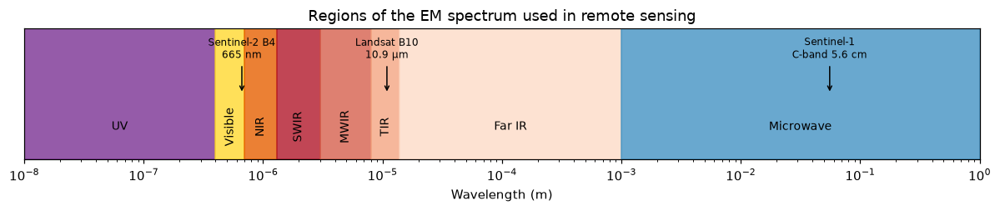

In [1]:

# This code creates a visual representation of the regions of the electromagnetic (EM) spectrum
# that are used in remote sensing, and highlights the typical wavelength ranges and sensor channels.
# Here is what each part does:

# %matplotlib inline: ensures that plots display inline when using a Jupyter Notebook.

import warnings
warnings.filterwarnings("ignore", category=UserWarning)      # Suppress UserWarnings (usually from matplotlib)

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

# Set figure display parameters for clarity in the notebook.
plt.rcParams.update({
    "figure.dpi": 110,    # Higher DPI for sharper figures
    "axes.grid": True,    # Show grid by default
    "grid.alpha": 0.3     # Light grid lines
})

# Define the major EM spectrum regions used in remote sensing as a list of tuples:
# Each tuple = (region_name, wavelength_start [m], wavelength_end [m], color_as_hex)
regions = [
    ("UV", 1e-8, 4e-7, "#7b3294"),
    ("Visible", 4e-7, 7e-7, "#ffd92f"),
    ("NIR", 7e-7, 1.3e-6, "#e66101"),
    ("SWIR", 1.3e-6, 3e-6, "#b2182b"),
    ("MWIR", 3e-6, 8e-6, "#d6604d"),
    ("TIR", 8e-6, 1.4e-5, "#f4a582"),
    ("Far IR", 1.4e-5, 1e-3, "#fddbc7"),
    ("Microwave", 1e-3, 1.0, "#4393c3"),
]

# Create a figure and axes object for the plot.
fig, ax = plt.subplots(figsize=(11, 2.4))

# Plot each region as a colored band (axvspan) and add its label:
for name, a, b, col in regions:
    ax.axvspan(a, b, color=col, alpha=0.8)                       # Fill band for each spectrum region
    # Place region name at geometric mean (center in log space); vertical if narrow region
    ax.text(np.sqrt(a * b), 0.5, name, ha="center", va="center",
            fontsize=9, rotation=90 if b / a < 3 else 0)

# Add annotations for notable remote sensing satellite sensors and their wavelengths:
for label, wl in [
    ("Sentinel-2 B4\n665 nm", 665e-9),
    ("Landsat B10\n10.9 µm", 10.9e-6),
    ("Sentinel-1\nC-band 5.6 cm", 0.0556),
]:
    # Draw an arrow and label at the corresponding wavelength
    ax.annotate(
        label, (wl, 1.0), xytext=(wl, 1.55), ha="center", fontsize=8,
        arrowprops=dict(arrowstyle="->")
    )

# Final plot settings:
ax.set_xscale("log")                                   # X axis as log scale (for wavelength)
ax.set_xlim(1e-8, 1)                                   # Range: 10 nm to 1 m
ax.set_ylim(0, 2)                                      # Unused y scale, for display
ax.set_yticks([])                                      # Hide y-axis ticks
ax.set_xlabel("Wavelength (m)")                        # Label x-axis
ax.set_title("Regions of the EM spectrum used in remote sensing")  # Set plot title
ax.grid(False)                                         # Remove default grid (already colored regions)
plt.tight_layout()                                     # Adjust layout to fit
plt.show()                                             # Display the plot

In [2]:
# This code calculates and prints the wavelength (λ), frequency (ν), and energy per photon for different types of electromagnetic radiation relevant to remote sensing.
# Physical constants:
h = 6.626e-34  # Planck constant in joule-seconds (J·s)
c = 2.998e8    # Speed of light in meters per second (m/s)

# List of named wavelengths in meters for common remote sensing wavebands:
bands = [
    ("Blue light", 0.49e-6),      # Visible blue
    ("NIR", 0.86e-6),             # Near-infrared
    ("Thermal IR", 10.9e-6),      # Thermal infrared
    ("C-band radar", 0.0556),     # Microwave (C-band radar)
]

# Calculate and print properties for each wavelength:
for name, wl in bands:
    frequency = c / wl                # Frequency in Hz
    photon_energy = h * frequency     # Photon energy in joules
    # wavelength, frequency and photon energy of each region
    print(f"{name:13s} λ = {wl:9.3e} m   ν = {frequency:9.3e} Hz   photon energy = {photon_energy:9.3e} J")

Blue light    λ = 4.900e-07 m   ν = 6.118e+14 Hz   photon energy = 4.054e-19 J
NIR           λ = 8.600e-07 m   ν = 3.486e+14 Hz   photon energy = 2.310e-19 J
Thermal IR    λ = 1.090e-05 m   ν = 2.750e+13 Hz   photon energy = 1.822e-20 J
C-band radar  λ = 5.560e-02 m   ν = 5.392e+09 Hz   photon energy = 3.573e-24 J


A blue photon carries about 100,000 times more energy than a C-band radar photon. That is why
optical detectors count photons with semiconductors while radar receivers measure the
amplitude and phase of a wave, and why microwave radiation passes through clouds that block
visible light.

### Blackbody radiation: why the Sun and the Earth shine in different bands

Every object above absolute zero emits radiation. For an ideal emitter (a *blackbody*) the
spectral radiance at temperature $T$ follows **Planck's law**:

$$B_\lambda(T) = \frac{2hc^2}{\lambda^5} \, \frac{1}{e^{hc/(\lambda k_B T)} - 1}$$

Two consequences follow:

* **Wien's displacement law:** the wavelength of peak emission is
  $\lambda_{max} = 2898\,\mu m\,K / T$.
* **Stefan-Boltzmann law:** the total emitted power grows as $M = \varepsilon\sigma T^4$, where
  $\sigma = 5.67\times10^{-8}\,W\,m^{-2}K^{-4}$ and $\varepsilon \le 1$ is the **emissivity**.
  Real surfaces are *grey bodies* with $\varepsilon$ between about 0.9 (dry soil) and 0.99
  (water), which is why thermal remote sensing must correct for emissivity.

Comparing the Sun (≈5,778 K) with the Earth's surface (≈300 K) explains the split between
*reflective* and *emissive* remote sensing.


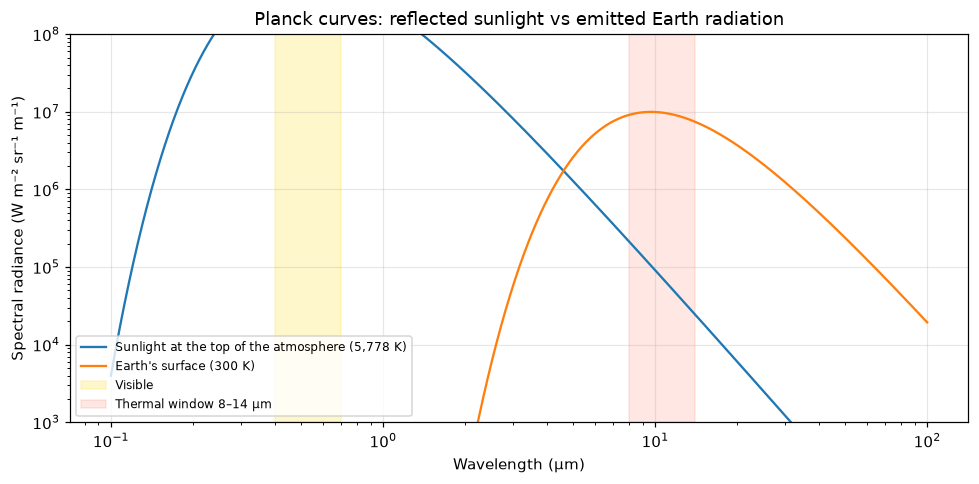

Sun          T =  5778 K  → peak emission at   0.50 µm,  σT⁴ =   63,196,527 W/m²
Earth        T =   300 K  → peak emission at   9.66 µm,  σT⁴ =          459 W/m²
Forest fire  T =  1000 K  → peak emission at   2.90 µm,  σT⁴ =       56,700 W/m²
Sunlight and Earth emission are equal near 4.6 µm


In [3]:
# This code compares the blackbody radiation curves (spectral radiance) of the Sun and the Earth,
# and illustrates why they emit at very different wavelengths.

# Boltzmann constant in J/K
kB = 1.381e-23

# Define a range of wavelengths in meters: from 0.1 µm to 100 µm (for plotting)
wl = np.logspace(-7, -4, 2000)  # 1e-7 m = 0.1 µm, 1e-4 m = 100 µm

# Planck's law: returns spectral radiance B_lambda for wavelength(s) wl [m] and temperature T [K]
def planck(wl, T):
    # The formula returns radiance in W m⁻² sr⁻¹ m⁻¹
    return 2 * h * c**2 / wl**5 / (np.exp(h * c / (wl * kB * T)) - 1)

# Get the radiance curves for the Sun (5778 K) and the Earth (300 K)
# The Sun's radiance is scaled to represent the apparent radiance at Earth's distance (by solid angle factor)
sun = planck(wl, 5778) * (6.96e8 / 1.496e11) ** 2     # (Sun radius / Earth-Sun distance)^2
earth = planck(wl, 300)  # Planck curve of the Earth's surface at 300 K

# Plot both curves on a log-log plot (wavelength in microns)
fig, ax = plt.subplots(figsize=(9, 4.5))
# sunlight on log-log axes (wavelength in µm)
ax.loglog(wl * 1e6, sun, label="Sunlight at the top of the atmosphere (5,778 K)")
ax.loglog(wl * 1e6, earth, label="Earth's surface (300 K)")  # Earth emission

# Highlight important spectral regions for remote sensing
# Visible window
ax.axvspan(0.4, 0.7, color="gold", alpha=0.2, label="Visible")
# Thermal IR "window" (where Earth's emission escapes to space most easily)
ax.axvspan(8, 14, color="tomato", alpha=0.15, label="Thermal window 8–14 µm")

ax.set_ylim(1e3, 1e8)  # radiance range shown
ax.set_xlabel("Wavelength (µm)")  # x label
ax.set_ylabel("Spectral radiance (W m⁻² sr⁻¹ m⁻¹)")  # y label
ax.legend(fontsize=8)  # legend
ax.set_title("Planck curves: reflected sunlight vs emitted Earth radiation")  # title
plt.tight_layout()  # arrange
plt.show()  # draw

# Compute and print the wavelength of peak emission (Wien's law) and total radiated power (Stefan–Boltzmann law)
for name, T in [("Sun", 5778), ("Earth", 300), ("Forest fire", 1000)]:
    peak = 2898 / T  # Wien's law: peak wavelength in µm
    total = 5.67e-8 * T**4  # Stefan–Boltzmann law: total emittance in W/m²
    # peak wavelength (Wien) and total emitted power (Stefan-Boltzmann)
    print(f"{name:12s} T = {T:5d} K  → peak emission at {peak:6.2f} µm,  σT⁴ = {total:12,.0f} W/m²")

# Find the wavelength where Sun and Earth radiance curves cross (emitted power equal)
crossover = wl[np.argmin(np.abs(np.log(sun) - np.log(earth)))] * 1e6  # Convert to µm
print(f"Sunlight and Earth emission are equal near {crossover:.1f} µm")  # where the two curves cross

**Interpretation.** Sunlight peaks around 0.5 µm (green light) and dominates below about
4 µm, so optical sensors in the VIS, NIR and SWIR measure *reflected* solar energy. Beyond
roughly 4 µm the Earth's own emission takes over, so thermal sensors measure *temperature*.
A forest fire at 1,000 K peaks near 2.9 µm and radiates more than 100 times as much power per
square metre as the ground around it, which is why fire products use mid-infrared bands.

### The atmosphere: scattering, absorption and windows

Radiation crosses the atmosphere twice in passive optical remote sensing (Sun → surface →
sensor). Two processes change it on the way.

**Scattering** redirects radiation. Its strength depends on the size of the particle relative
to the wavelength:

| Type | Particles | Wavelength dependence | Visible effect |
|---|---|---|---|
| **Rayleigh** | Gas molecules (≪ λ) | $\propto \lambda^{-4}$ | Blue sky; haze strongest in blue bands |
| **Mie** | Aerosols, smoke, dust (≈ λ) | roughly $\lambda^{-1}$ to $\lambda^{0}$ | Hazy, washed-out images |
| **Non-selective** | Cloud droplets, ice (≫ λ) | none | White clouds |

Scattered light that reaches the sensor without touching the surface is **path radiance**. It
brightens dark targets, especially in the blue, and lowers image contrast. Atmospheric
correction (the *Processing levels: from DN to physical units* section) removes it.

**Absorption** removes energy at specific wavelengths: ozone (O₃) in the ultraviolet, water
vapour (H₂O) near 0.94, 1.14, 1.38, 1.87 and 2.7 µm and above 5 µm, carbon dioxide (CO₂) near
2.0, 4.3 and 15 µm, and oxygen (O₂) at 0.76 µm. The spectral regions where the atmosphere is
mostly transparent are the **atmospheric windows**, and sensor bands are placed inside them:

| Window | Used by |
|---|---|
| 0.3 to 1.3 µm (VIS-NIR) | All multispectral sensors |
| 1.5 to 1.8 µm and 2.0 to 2.4 µm (SWIR) | Landsat B6/B7, Sentinel-2 B11/B12 |
| 3.5 to 4.2 µm (MWIR) | Fire detection (MODIS, VIIRS) |
| 8 to 14 µm (TIR), split by ozone at 9.6 µm | Landsat B10/B11, ECOSTRESS |
| > 1 cm (microwave) | Radar; almost unaffected by clouds |

The opposite trick is also useful: bands placed *inside* an absorption feature measure the
absorber itself. Landsat 8 band 9 (1.37 µm) sits in a strong water-vapour band, so the ground
is invisible and only high cirrus clouds appear bright.

The code below compares the relative strength of Rayleigh scattering across the Landsat 8
reflective bands. The *Physics in the data: the Sun's spectrum and atmospheric scattering* section tests this $\lambda^{-4}$ law on a real image.


In [4]:
# This cell shows why blue light is scattered much more than red light.
#
# Rayleigh scattering (molecules in clear air) gets weaker as wavelength gets longer.
# The strength scales as 1 / wavelength^4. Dividing each Landsat band by the red band
# and raising that ratio to the power -4 answers: "how many times more does this band
# scatter than red?"
#
# 1. Store the centre wavelength (micrometres) of each Landsat 8 reflective band.
# 2. Compute the Rayleigh ratio relative to the red band.
# 3. Show both numbers side by side. Coastal and blue come out several times stronger
#    than red; the SWIR bands barely scatter at all.

oli = pd.Series({"coastal (B1)": 0.443, "blue (B2)": 0.482, "green (B3)": 0.561, "red (B4)": 0.655,
                 "nir (B5)": 0.865, "swir16 (B6)": 1.609, "swir22 (B7)": 2.201}, name="centre_um")
# (λ_band / λ_red) ^ -4. A value of 4 means "scattered four times as much as red".
rayleigh = (oli / oli["red (B4)"]) ** -4
# band centres and their relative Rayleigh scattering
pd.DataFrame({"centre (µm)": oli, "Rayleigh scattering relative to red": rayleigh.round(2)})

,centre (µm),Rayleigh scattering relative to red
coastal (B1),0.443,4.78
blue (B2),0.482,3.41
green (B3),0.561,1.86
red (B4),0.655,1.00
nir (B5),0.865,0.33
swir16 (B6),1.609,0.03
swir22 (B7),2.201,0.01


Blue light is scattered about three times more strongly than red, and the coastal/aerosol band
almost five times more. SWIR bands are nearly free of molecular scattering, which is why SWIR
composites look sharp even on hazy days.

### Energy-matter interactions at the surface

Radiation reaching the surface is split three ways. By conservation of energy, at each
wavelength

$$E_I(\lambda) = E_R(\lambda) + E_A(\lambda) + E_T(\lambda),$$

the incident energy equals the reflected, absorbed and transmitted parts. Dividing by $E_I$
gives the reflectance, absorptance and transmittance, which sum to one. Remote sensing of
reflected energy measures the **spectral reflectance**

$$\rho(\lambda) = \frac{E_R(\lambda)}{E_I(\lambda)},$$

and the curve of $\rho$ against wavelength is the material's **spectral signature**
(the *Spectral signatures from real images* section). Kirchhoff's law links absorption and emission: a surface in thermal equilibrium
emits as well as it absorbs at each wavelength ($\varepsilon_\lambda = \alpha_\lambda$), so for
an opaque surface $\varepsilon_\lambda = 1 - \rho_\lambda$. That is why water, a poor reflector
in the thermal infrared, is an almost perfect emitter.

The **geometry** of reflection matters too:

* A **specular** surface (calm water, smooth roofs) reflects like a mirror. It looks either very
  dark or, at the mirror angle, dazzlingly bright (sun glint).
* A **Lambertian** (perfectly diffuse) surface reflects equally in all directions, so its
  radiance does not depend on viewing angle. Most land surfaces are treated as approximately
  Lambertian.
* Real surfaces lie in between. Their directional behaviour is described by the
  **bidirectional reflectance distribution function (BRDF)**: forests look brighter with the Sun
  behind the observer (the "hot spot") because shadows are hidden.

For microwaves the controlling properties are different: surface **roughness** relative to the
wavelength, **dielectric constant** (mainly moisture) and **geometry** (corner reflectors in
cities, volume scattering in canopies). The radar notebooks (07_03) develop these for SAR.

### Radiometric quantities and the radiative transfer equation

| Quantity | Symbol | Unit | Meaning |
|---|---|---|---|
| Radiant flux | Φ | W | Energy per unit time |
| Irradiance | E | W m⁻² | Flux arriving on a surface |
| Exitance | M | W m⁻² | Flux leaving a surface |
| Radiance | L | W m⁻² sr⁻¹ µm⁻¹ | Flux per area, per solid angle, per wavelength: what a sensor measures |
| Reflectance | ρ |, | Ratio of reflected to incident flux (0 to 1) |

For a Lambertian surface the radiance reaching a sensor at the top of the atmosphere is

$$L_{sensor}(\lambda) = \frac{\rho(\lambda)\,E_{sun}(\lambda)\cos\theta_s\,T_{\downarrow}(\lambda)\,T_{\uparrow}(\lambda)}{\pi\,d^2}
+ L_{path}(\lambda),$$

with exo-atmospheric solar irradiance $E_{sun}$, solar zenith angle $\theta_s$, Earth-Sun
distance $d$ (astronomical units), downward and upward atmospheric transmittances $T$, and
path radiance $L_{path}$. Setting $T = 1$ and $L_{path} = 0$ and solving for $\rho$ gives the
**top-of-atmosphere (TOA) reflectance**

$$\rho_{TOA} = \frac{\pi\,L_{sensor}\,d^2}{E_{sun}\cos\theta_s}.$$

Estimating $T$ and $L_{path}$ (from radiative transfer models, or from dark objects in the
image) gives **surface reflectance**, the starting point of most analysis. The *Physics in the data: the Sun's spectrum and atmospheric scattering* section uses this
equation to recover the solar spectrum from a real Landsat metadata file.


## Branches of remote sensing

Remote sensing is a family of techniques. They are usually grouped four ways.

### By energy source

| Branch | Principle | Strengths | Limitations |
|---|---|---|---|
| **Passive** | Records natural energy: reflected sunlight or emitted heat | Rich spectral information, long archives, cheap | Needs daylight (optical) and clear skies |
| **Active** | Sends its own pulse and records the echo | Day and night; radar sees through clouds; measures range and structure | Complex geometry, speckle, fewer bands |

### By spectral region

| Branch | Wavelengths | What it measures | Typical sensors | In this course |
|---|---|---|---|---|
| **Optical (multispectral)** | 0.4 to 2.5 µm, 4 to 15 bands | Surface reflectance: vegetation, water, soils, built-up areas | Landsat 8/9, Sentinel-2, MODIS, PlanetScope | Part II (07_02) |
| **Hyperspectral (imaging spectroscopy)** | 0.4 to 2.5 µm, 100 to 400 narrow contiguous bands | Detailed spectra: minerals, plant pigments, water quality | EnMAP, PRISMA, EMIT, AVIRIS | 07_06 |
| **Thermal infrared** | 3 to 14 µm | Surface temperature and emissivity | Landsat TIRS, ECOSTRESS, MODIS | 07_02, the *Processing levels: from DN to physical units* section |
| **Passive microwave** | 1 mm-30 cm | Natural microwave emission: soil moisture, sea ice, rainfall | SMAP, SMOS, AMSR2 |, |
| **Radar (SAR)** | 1 cm-1 m | Backscatter, phase and polarisation: structure, moisture, deformation (InSAR) | Sentinel-1, NISAR, RADARSAT, ALOS-2 | Part III (07_03) |
| **Lidar** | Laser, usually 532 or 1064 nm | Range to targets: terrain, canopy height, 3-D structure | Airborne lidar (USGS 3DEP), GEDI, ICESat-2 | 07_05 |

### By platform

| Platform | Altitude | Typical pixel size | Examples |
|---|---|---|---|
| Ground and proximal | 0 to 100 m | mm-cm | Spectroradiometers, terrestrial lidar, phenocams |
| Unoccupied aerial vehicles (UAV, drones) | 30 to 120 m | 1 to 10 cm | RGB, multispectral and thermal drone cameras (07_04) |
| Aircraft | 1 to 20 km | 0.1 to 5 m | NAIP aerial photography, AVIRIS, airborne lidar |
| Low Earth orbit (LEO) satellites | 400 to 900 km | 0.3 m-1 km | Landsat, Sentinel, WorldView |
| Geostationary satellites | 35,786 km | 0.5 to 2 km | GOES, Himawari, Meteosat: images every 5 to 15 minutes |

Most land-imaging satellites fly **sun-synchronous polar orbits**, crossing the equator at the
same local time on every pass (about 10:00 to 10:30 for Landsat and Sentinel-2), so illumination
is comparable between dates.

### By spectral resolution

* **Panchromatic:** one broad band (for example Landsat 8 band 8, 15 m), finest spatial detail.
* **Multispectral:** a few broad bands (Landsat, Sentinel-2).
* **Hyperspectral:** hundreds of narrow, contiguous bands, enough to identify materials by the
  shape of their spectra.

### Related disciplines

**Photogrammetry** measures geometry from overlapping images (digital surface models,
orthomosaics; the basis of UAV mapping). **Geodesy and GNSS** provide the positioning that
georeferences every pixel. **Geographic information science** combines remote sensing layers
with other spatial data, which is what the rest of GeoLattice does.


## Applications

Remote sensing is used wherever a quantity varies over space and time and is hard to measure
on the ground everywhere.

| Domain | Typical questions | Data and methods | `geolattice.rsense` tools |
|---|---|---|---|
| **Agriculture** | Crop type, crop health, yield, irrigation, drought | NDVI/EVI time series, phenology, SAR for cloudy seasons, thermal water stress | `optical.index`, `timeseries.phenology`, `timeseries.vhi`, `uav.cwsi` |
| **Forestry** | Forest cover and loss, canopy height, biomass, fire | Change detection, lidar canopy height, GEDI, burn indices (NBR) | `classify.cva`, `lidar.chm`, `lidar.detect_trees`, `timeseries.bfast_monitor` |
| **Water resources and floods** | Surface water extent, flood mapping, water quality | NDWI/MNDWI, SAR backscatter thresholds, optical-SAR fusion | `sar.flood_map`, `optical.index`, `fusion.sar_gap_fill` |
| **Urban studies** | Urban growth, impervious surfaces, heat islands | Classification, NDBI, land surface temperature | `classify.Classifier`, `optical.landsat_lst`, `optical.surface_urban_heat_island` |
| **Natural hazards** | Earthquakes, landslides, subsidence, volcanoes | InSAR deformation, change detection, rapid mapping | `insar.interferogram`, `insar.sbas_inversion`, `sar.change_map` |
| **Climate and cryosphere** | Snow cover, glaciers, sea ice, surface temperature trends | NDSI, thermal time series, passive microwave | `optical.index`, `timeseries.anomaly`, `timeseries.ccdc` |
| **Oceans and coasts** | Ocean colour, sea surface temperature, shoreline change, oil spills | Chlorophyll indices, thermal bands, SAR | `sar.oil_spill_detection`, `sar.cfar` (ship detection) |
| **Geology and soils** | Mineral mapping, soil organic carbon, erosion | SWIR and hyperspectral spectra, terrain analysis | `optical.unmix`, `lidar.geomorphons` |
| **Environmental and public health** | Heat exposure, air quality, vector habitats, green space | LST, vegetation indices, land cover linked to health records | `optical.landsat_lst`, `core.zonal_stats` |
| **Biodiversity and conservation** | Habitat mapping, protected-area monitoring | Classification, structure from lidar, explainable ML | `classify`, `xai.aoa`, `xai.SpatialBlockCV` |

The capstone notebooks in `08_11_Capstones` work through agriculture, hazards, forestry,
precision agriculture and environmental health end to end.


## Remote sensing in GeoLattice: `geolattice.rsense`

GeoLattice bundles a complete remote sensing toolkit in the subpackage **`geolattice.rsense`**. Rasters
are `xarray` objects with a coordinate reference system (through `rioxarray`), and every
array operation can run on the CPU (NumPy) or on an NVIDIA GPU (CuPy) through one backend
switch. Install it with

```bash
pip install "geolattice[rsense]"          # core: xarray, rioxarray, rasterio, scikit-image
pip install "geolattice[rsense-all]"      # data access, SAR, InSAR, lidar, UAV, ML, DL, XAI, viz, scaling
```

and import it as `import geolattice.rsense as rs`. Heavy optional dependencies (PyTorch, Earth
Engine, PDAL, ...) are imported only when a function needs them.

| Submodule | Purpose |
|---|---|
| `backend` | Choose CPU or GPU (`set_backend`), move arrays (`to_device`, `to_cpu`), precision and memory |
| `core` | Read and write rasters (GeoTIFF, COG, NetCDF, HDF, Zarr, SAFE), reproject, clip, mosaic, tile, zonal statistics, data cubes and point clouds |
| `access` | Search and download data: STAC (Earth Search, Planetary Computer), Google Earth Engine, ASF (SAR), Copernicus Data Space (CDSE), NASA Earthdata |
| `optical` | Sensor loaders (Landsat, Sentinel-2, HLS, MODIS), scaling, cloud masks, 100+ spectral indices, compositing, radiometric and atmospheric correction, land surface temperature, spectral unmixing |
| `sar` | Sentinel-1 calibration, speckle filters, multilooking, dB conversion, PolSAR decompositions, change detection, flood, ship and oil-spill mapping |
| `insar` | Interferograms, filtering, phase unwrapping, atmospheric correction, SBAS time series, line-of-sight to vertical motion; HyP3, ISCE and MintPy interfaces |
| `uav` | OpenDroneMap processing, radiometric calibration, canopy height and cover, plant counting, thermal water stress |
| `lidar` | Point-cloud I/O, ground classification, DTM/DSM/CHM, terrain derivatives, tree detection, forest metrics, GEDI and ICESat-2 |
| `timeseries` | Smoothing (Savitzky-Golay, Whittaker), harmonic fits, phenology, anomalies, drought indices, BFAST-style monitoring, CCDC |
| `classify` | Pixel classifiers, clustering, object-based image analysis, change detection, accuracy assessment (Olofsson area estimates) |
| `dl` | Deep learning: tile datasets, U-Net and detection models, training, inference, TorchGeo and foundation-model adapters |
| `fusion` | STARFM spatiotemporal fusion, optical-SAR and lidar-optical fusion |
| `xai` | Explainable and trustworthy ML: permutation and SHAP importance, spatial cross-validation, area of applicability, conformal prediction |
| `viz` | RGB composites, stretches, raster, time-series and point-cloud plots, interactive maps |
| `scale` | Dask clusters, Zarr data cubes, STAC export for large-area processing |
| `apps` | Streamlit app templates (change viewer, flood mapper, index explorer) |

`geolattice.rsense` also registers an **`.rs` accessor** on every `xarray` object, so common steps
chain naturally, for example `ds.rs.scale().rs.mask_clouds().rs.index("NDVI")`.

The next cells list every public function and class directly from the installed package, with
the first line of its documentation.


In [5]:
# This cell checks that geolattice and geolattice.rsense import, and reports which compute
# backend is active.
#
# 1. importlib and inspect are used in the next cells to walk the public API.
# 2. Import the top-level package and the remote-sensing subpackage.
# 3. Print versions, the backend in use (cpu or cuda), and every backend this
#    machine can actually run.

import importlib          # load a submodule by its name string
import inspect            # read functions, classes and docstrings

import geolattice  # GeoLattice
import geolattice.rsense as rs  # GeoLattice remote sensing subpackage

print("geolattice", geolattice.__version__, "| geolattice.rsense", rs.__version__)  # versions
# array backend in use and the ones available
print("backend:", rs.get_backend(), "| available backends:", rs.available_backends())

geolattice 0.3.35 | geolattice.rsense 0.3.35
backend: cpu | available backends: ['cpu', 'cuda']


In [6]:
# This block of code dynamically inspects all public functions and classes in the submodules of `geolattice.rsense`
# and summarizes them in a pandas DataFrame. It then prints a summary table of the counts of functions and classes per submodule.

# List of submodules in geolattice.rsense to inspect
SUBMODULES = [
    "backend", "core", "access", "optical", "sar", "insar", "uav", "lidar",
    "timeseries", "classify", "dl", "fusion", "xai", "viz", "scale", "apps"
]

rows = []  # one row per public function or class

# For each submodule, import it, retrieve its public API, and extract all functions/classes with their descriptions
for sub in SUBMODULES:
    # Dynamically import the submodule
    mod = importlib.import_module(f"geolattice.rsense.{sub}")
    # Get the list of public names, preferring __all__ if present, else all non-private attributes
    public_names = getattr(mod, "__all__", [n for n in dir(mod) if not n.startswith("_")])

    for name in public_names:  # every public name of the submodule
        obj = getattr(mod, name, None)  # the object behind the name
        # Only process functions and classes
        if not (inspect.isfunction(obj) or inspect.isclass(obj)):
            continue
        # Only include objects declared in geolattice.rsense (skip re-exported names from other libraries)
        if not getattr(obj, "__module__", "").startswith("geolattice.rsense"):
            continue
        # Extract the first line of the object's docstring as its description
        doc = (inspect.getdoc(obj) or "").split("\n")[0]
        rows.append({  # one row: submodule, name, kind and description
            "submodule": sub,
            "name": name,
            "kind": "class" if inspect.isclass(obj) else "function",
            "description": doc
        })

# Create a DataFrame to organize the API entries
api = pd.DataFrame(rows)

# Print the total number of discovered public API entries
print(f"{len(api)} public functions and classes in geolattice.rsense")

# Group the DataFrame by submodule, aggregating counts of functions and classes, and display as a transposed table
print(
    api.groupby("submodule", sort=False)
       .agg(
           functions=("kind", lambda k: int((k == "function").sum())),
           classes=("kind", lambda k: int((k == "class").sum()))
       ).T
)
                             

478 public functions and classes in geolattice.rsense
submodule  backend  core  access  optical  sar  insar  uav  lidar  timeseries  \
functions       22    20      14       34  140     45   15     95          12   
classes          1     3       0        0    0      0    0      1           0   

submodule  classify  dl  fusion  xai  viz  scale  apps  
functions        12  27       6    7    7      5     3  
classes           1   3       0    5    0      0     0  


In [7]:
# Set pandas to display up to 110 characters per column, so descriptions are not truncated.
pd.set_option("display.max_colwidth", 110)

# Loop through each submodule in the API DataFrame, preserving the defined order.
for sub, grp in api.groupby("submodule", sort=False):
    # Print a header for the submodule, showing the full import path and number of entries.
    print(f"\n=== geolattice.rsense.{sub}  ({len(grp)}) " + "=" * 40)
    # For each API entry (function or class) in the submodule, print its name and the first 105 characters of its description.
    for _, r in grp.iterrows():
        print(f"  {r['name']:<28s} {r['description'][:105]}")  # name and the start of its description
 


=== geolattice.rsense.backend  (23) ========================================
  Backend                      An active compute backend.
  array_module                 Return the array module that owns ``arr`` (works for NumPy, CuPy and Dask chunks).
  as_compute_dtype             Cast integer or mismatched float data to the compute dtype (no copy if already right).
  autocast                     PyTorch mixed-precision context on the active backend.
  available_backends           Return the backends usable on this machine, e.g. ``['cpu', 'cuda']``.
  clear_cache                  Release cached GPU memory held by CuPy's pool and PyTorch's allocator.
  compute_dtype                dtype used for array math under the current policy.
  device                       Temporarily switch backend::
  fft                          
  free_gpu_memory_bytes        Free memory on the active CUDA device, or ``None`` on CPU.
  get_backend                  Return the currently active backend.
  get_prec

In [8]:
# This code demonstrates how to inspect and list the custom accessor methods available for xarray's
# Dataset and DataArray objects in the geolattice.rsense module.

import xarray as xr  # xarray is a package for N-dimensional labeled arrays (useful for remote sensing).

# Import custom accessors for xarray, which add "rs" property to xarray objects for remote sensing methods.
from geolattice.rsense.accessor import RSDataArrayAccessor, RSDatasetAccessor

# Get a list of all public (non-private) methods provided by the RSDatasetAccessor (xarray.Dataset.rs)
ds_methods = [m for m in dir(RSDatasetAccessor) if not m.startswith("_")]

# Get a list of all public (non-private) methods provided by the RSDataArrayAccessor (xarray.DataArray.rs)
da_methods = [m for m in dir(RSDataArrayAccessor) if not m.startswith("_")]

# Print available methods for the custom accessors attached to Dataset and DataArray
print("Dataset.rs   :", ", ".join(ds_methods))
print("DataArray.rs :", ", ".join(da_methods))  # the methods the .rs accessor adds to a DataArray

Dataset.rs   : clip, cloud_mask, composite, index, mask_clouds, reproject, scale, sensor, to_cpu, to_device, with_sensor, write
DataArray.rs : apply_tiled, clip, cloud_mask, composite, index, mask_clouds, reproject, scale, sensor, to_cpu, to_device, with_sensor, write, zonal_stats


To read the full documentation of any entry, use `help()`, for example
`help(rs.optical.index)`, or `rs.optical.index?` in Jupyter.


## Setup and data

This module uses three scenes from the [GeoLattice data folder](https://www.dropbox.com/scl/fo/58n9t8sewax7pffrroxd3/AIWTrjKzklRedtYx0mczwcc?rlkey=0fat0am1b0aai5pieqyx0633j&dl=0) in Dropbox

| Dataset | Folder | Contents | Used for |
|---|---|---|---|
| **Landsat 8 OLI/TIRS Level-1** | `Landsat8_RAW/` | Collection 1 L1TP subset (16 × 15 km), path 16 / row 30, acquired 2016-09-27: farmland between Canandaigua and Seneca lakes in the Finger Lakes region of New York (42.84°N, 77.13°W; UTM 18N, 30 m); bands 1 to 11, quality band and the `MTL.txt` metadata file | Radiometric calibration, spectral indices, thermal infrared, scattering |
| **Sentinel-2 MSI** | `Sentinel_2/` | 10 bands resampled to 10 m over a 2.1 × 1.7 km area in Amherst, near Buffalo, New York (43.00°N, 78.81°W; UTM 17N), values are reflectance × 10,000; 108 labelled ground-truth polygons (`GroundTruth_data.shp`) | Spectral signatures, red edge, spatial resolution |
| **Landsat 9 OLI-2 Level-2** | `LC09_L2SP_138043_20221216_20221223_02_T1/` | Collection 2 surface reflectance, path 138 / row 43, 2022-12-16, northwestern Bangladesh (window centred near 24.58°N, 88.96°E) | Scaling Level-2 products |

**Getting more data.** The [PyGIS Explorer app](https://zia207-pygis-explorer-app-ou8ehd.streamlit.app/)
lets you draw an area of interest, search a catalogue and download the scenes you select from
Earth Search (AWS), Microsoft Planetary Computer, Copernicus Data Space (CDSE), NOAA Digital
Coast and USGS 3DEP lidar. The same searches are available in code through
`rs.access.stac_search`, `rs.access.stac_load`, `rs.access.cdse_search` and
`rs.access.earthdata_search` (notebook 09_01_03).

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [9]:
# Import necessary libraries
from pathlib import Path
import geopandas as gpd  # vector data

# Set the base data directory
DATA = Path("../../../../Data/00_shared/data_remote_sensing")

# Set the directory and ID string for the Landsat 8 imagery (Level 1 product)
L8_DIR = DATA / "Landsat8_RAW"
L8_ID = "LC08_L1TP_016030_20160927_20170220_01_T1"  # Landsat 8 scene ID

# Parse the Landsat metadata file using the 'parse_mtl' function from rs.optical
# This reads key-value pairs describing the scene characteristics
mtl = rs.optical.parse_mtl(L8_DIR / f"{L8_ID}_MTL.txt")

# List of metadata fields of interest for display
fields_of_interest = [
    "SPACECRAFT_ID",
    "SENSOR_ID",
    "DATE_ACQUIRED",
    "SCENE_CENTER_TIME",
    "WRS_PATH",
    "WRS_ROW",
    "CLOUD_COVER",
    "SUN_ELEVATION",
    "SUN_AZIMUTH",
    "EARTH_SUN_DISTANCE"
]

# Print each selected metadata attribute and its value, formatting key names for clarity
for key in fields_of_interest:
    print(f"{key:20s} {mtl[key]}")  # field name and value

SPACECRAFT_ID        LANDSAT_8
SENSOR_ID            OLI_TIRS
DATE_ACQUIRED        2016-09-27
SCENE_CENTER_TIME    15:51:39.9873550Z
WRS_PATH             16.0
WRS_ROW              30.0
CLOUD_COVER          18.77
SUN_ELEVATION        42.38608767
SUN_AZIMUTH          157.00326767
EARTH_SUN_DISTANCE   1.0021199


In [10]:
# Define a mapping from Landsat 8 band numbers to their descriptive names
L8_BANDS = {
    1: "coastal",   # Coastal/aerosol band
    2: "blue",      # Blue band
    3: "green",     # Green band
    4: "red",       # Red band
    5: "nir",       # Near-infrared band
    6: "swir16",    # Shortwave infrared 1 (1.6 μm)
    7: "swir22",    # Shortwave infrared 2 (2.2 μm)
    9: "cirrus",    # Cirrus cloud band
    10: "tir1",     # Thermal infrared 1
    11: "tir2"      # Thermal infrared 2
}

# Read each selected Landsat band into an xarray Dataset.
# - The 'rs.read' function loads the raster file (.TIF) for each band.
# - .squeeze("band", drop=True) ensures any singleton 'band' dimensions are removed for 2D array access.
# - Each band gets mapped to its descriptive name as a data variable in the Dataset.
dn = xr.Dataset({
    name: rs.read(L8_DIR / f"{L8_ID}_B{b}.TIF").squeeze("band", drop=True)
    for b, name in L8_BANDS.items()
})

# Write the coordinate reference system (CRS) metadata into the dataset using the CRS from the red band
dn = dn.rio.write_crs(dn["red"].rio.crs)

# Print the CRS, the size of each dimension (number of pixels), and the pixel size in meters.
print(dn.rio.crs, dict(dn.sizes), f"{abs(float(dn.x[1] - dn.x[0])):.0f} m pixels")

# Show a summary of the resulting dataset
dn

EPSG:32618 {'x': 541, 'y': 504} 30 m pixels


<xarray.Dataset> Size: 11MB
Dimensions:      (x: 541, y: 504)
Coordinates:
  * x            (x) float64 4kB 3.182e+05 3.182e+05 ... 3.344e+05 3.344e+05
  * y            (y) float64 4kB 4.753e+06 4.753e+06 ... 4.738e+06 4.738e+06
    spatial_ref  int64 8B 0
Data variables:
    coastal      (y, x) float32 1MB ...
    blue         (y, x) float32 1MB ...
    green        (y, x) float32 1MB ...
    red          (y, x) float32 1MB ...
    nir          (y, x) float32 1MB ...
    swir16       (y, x) float32 1MB ...
    swir22       (y, x) float32 1MB ...
    cirrus       (y, x) float32 1MB ...
    tir1         (y, x) float32 1MB ...
    tir2         (y, x) float32 1MB ...

In [11]:
# Define the path to the Sentinel-2 data folder
S2_DIR = DATA / "Sentinel_2"

# Dictionary mapping Sentinel-2 band filenames to canonical band names
S2_BANDS = {
    "B2": "blue",
    "B3": "green",
    "B4": "red",
    "B5": "rededge1",
    "B6": "rededge2",
    "B8": "nir",
    "B8A": "nir08",
    "B11": "swir16",
    "B12": "swir22"
}

# Read each specified band into an xarray Dataset:
# - For each key:value pair (e.g., "B2": "blue") in S2_BANDS,
#   read the .tif file for that band from disk.
# - Remove any singleton (single-length) "band" dimension for a 2D array.
# - Scale the raw integer data to reflectance by dividing by 10,000.
# - Store each band as a variable with its canonical name in the Dataset.
s2 = xr.Dataset({
    name: rs.read(S2_DIR / f"{b}.tif").squeeze("band", drop=True) / 10000
    for b, name in S2_BANDS.items()
})

# Sentinel-2 GeoTIFFs carry no coordinate system metadata,
# so we assign the correct UTM 17N CRS (EPSG:32617) from documentation
s2 = s2.rio.write_crs("EPSG:32617")

# Load land use class information from a CSV, setting Class_ID as the index
# Resulting Series maps integer IDs to land use names
classes = pd.read_csv(S2_DIR / "Landuse_ID.csv").set_index("Class_ID")["Landuse"]

# Load ground truth polygons from a shapefile and set CRS to match the imagery
gt = gpd.read_file(S2_DIR / "GroundTruth_data.shp").set_crs("EPSG:32617")

# Filter out any polygons whose Class_ID does not exist in the land use mapping
# and create a copy to retain independence from the original DataFrame
gt = gt[gt["Class_ID"].isin(classes.index)].copy()

# Add a "Landuse" column to the polygons by mapping their Class_ID to descriptive names
gt["Landuse"] = gt["Class_ID"].map(classes)

# Print size information for the image data and the polygon counts per land use class
print(dict(s2.sizes), "| polygons per class:", gt["Landuse"].value_counts().to_dict())

{'x': 210, 'y': 170} | polygons per class: {'Building': 42, 'Parking/road/pavement': 28, 'Grass': 15, 'Tree/bushes': 14, 'Water': 5}


The Sentinel-2 folder also holds a file named `B7.tif`, but it is byte-for-byte identical to
`B6.tif`, so it cannot be band 7 and is left out. Nine polygons with class 0 have no label in
`Landuse_ID.csv` and are dropped.


## Where satellite bands sit on the spectrum

Sensors sample the spectrum in discrete **bands**. The central wavelengths below come from
the official sensor specifications. Sentinel-2 adds three narrow *red-edge* bands
(705 to 783 nm) that Landsat lacks; these respond strongly to chlorophyll content.


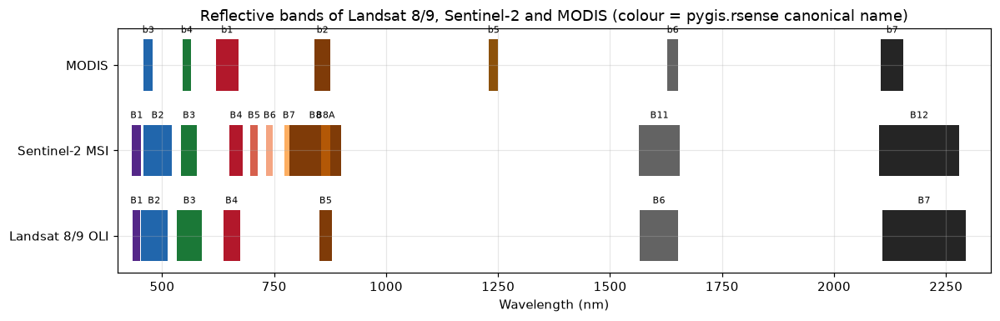

In [12]:
# Create a DataFrame describing the reflective bands for three satellite sensors:
# Landsat 8/9 OLI, Sentinel-2 MSI, and MODIS. Each row contains:
# - the sensor name
# - the band name as used by the sensor
# - the center wavelength for that band (in nanometers)
# - the wavelength width of the band (in nanometers)
# - the canonical name used by geolattice.rsense for that band
bands = pd.DataFrame([
    # sensor, band, centre (nm), width (nm), canonical name used by geolattice.rsense
    ("Landsat 8/9 OLI", "B1", 443, 16, "coastal"), 
    ("Landsat 8/9 OLI", "B2", 482, 60, "blue"),
    ("Landsat 8/9 OLI", "B3", 561, 57, "green"), 
    ("Landsat 8/9 OLI", "B4", 655, 37, "red"),
    ("Landsat 8/9 OLI", "B5", 865, 28, "nir"), 
    ("Landsat 8/9 OLI", "B6", 1609, 85, "swir16"),
    ("Landsat 8/9 OLI", "B7", 2201, 187, "swir22"),
    ("Sentinel-2 MSI", "B1", 443, 20, "coastal"), 
    ("Sentinel-2 MSI", "B2", 490, 65, "blue"),
    ("Sentinel-2 MSI", "B3", 560, 35, "green"), 
    ("Sentinel-2 MSI", "B4", 665, 30, "red"),
    ("Sentinel-2 MSI", "B5", 705, 15, "rededge1"), 
    ("Sentinel-2 MSI", "B6", 740, 15, "rededge2"),
    ("Sentinel-2 MSI", "B7", 783, 20, "rededge3"), 
    ("Sentinel-2 MSI", "B8", 842, 115, "nir"),
    ("Sentinel-2 MSI", "B8A", 865, 20, "nir08"), 
    ("Sentinel-2 MSI", "B11", 1610, 90, "swir16"),
    ("Sentinel-2 MSI", "B12", 2190, 180, "swir22"),
    ("MODIS", "b3", 469, 20, "blue"), 
    ("MODIS", "b4", 555, 20, "green"), 
    ("MODIS", "b1", 645, 50, "red"),
    ("MODIS", "b2", 858, 35, "nir"), 
    ("MODIS", "b5", 1240, 20, "swir12"),
    ("MODIS", "b6", 1640, 24, "swir16"), 
    ("MODIS", "b7", 2130, 50, "swir22"),
], columns=["sensor", "band", "centre_nm", "width_nm", "canonical"])

# Make a bar plot showing where these reflective bands are located on the spectrum for each sensor.
# Each horizontal bar represents a spectral band, its width equals the band wavelength range,
# and color corresponds to the canonical band name.
fig, ax = plt.subplots(figsize=(11, 3.6))
colours = {  # colour of each canonical band name
    "coastal": "#542788", "blue": "#2166ac", "green": "#1b7837", "red": "#b2182b",
    "rededge1": "#d6604d", "rededge2": "#f4a582", "rededge3": "#fdae61", "nir": "#7f3b08",
    "nir08": "#b35806", "swir12": "#8c510a", "swir16": "#636363", "swir22": "#252525"
}

# Group each sensor's bands and plot them row-by-row, coloring by canonical.
for i, (sensor, grp) in enumerate(bands.groupby("sensor", sort=False)):
    for _, b in grp.iterrows():  # each band of that sensor
        # Draw each band as a horizontal bar at the sensor's row with band width and centered at the central wavelength.
        ax.barh(i, b.width_nm, left=b.centre_nm - b.width_nm / 2, height=0.6, color=colours[b.canonical])
        # Place the band name just above the bar.
        ax.text(b.centre_nm, i + 0.38, b.band, ha="center", fontsize=7)

# Set axis labels and limits.
ax.set_yticks(range(3))
ax.set_yticklabels(bands.sensor.unique())  # sensor names on the y axis
ax.set_xlabel("Wavelength (nm)")  # x label
ax.set_xlim(400, 2350)  # visible to shortwave infrared
# title
ax.set_title("Reflective bands of Landsat 8/9, Sentinel-2 and MODIS (colour = geolattice.rsense canonical name)")
plt.tight_layout()  # arrange
plt.show()  # draw

`geolattice.rsense` refers to bands by these **canonical names** (`blue`, `red`, `nir`, `swir16`,
...) so the same index formula works for every sensor. It translates each product's own names
(`B04`, `SR_B4`, `sur_refl_b01`) automatically:


In [13]:
# Import the SENSOR_BANDS dictionary, which contains the mapping between canonical band names (like "blue", "nir", etc.)
# and each sensor's native band names for several optical satellite sensors.
from geolattice.rsense.optical import SENSOR_BANDS

# Build and display a DataFrame showing how the same canonical band (row; e.g., "blue") is called by each sensor (column):
# For each sensor, create a dictionary mapping the canonical name (e.g., "blue") to 
# a human-readable string listing all native band names for that sensor, joined by " / ".
# Collect these per-sensor dictionaries into a larger dictionary (columns).
# Finally, display the table, filling any missing bands with an en dash.
pd.DataFrame({
    s: {k: " / ".join(v) for k, v in SENSOR_BANDS[s].items()}
    for s in ["landsat", "sentinel2", "modis", "hls_s30"]
}).fillna("–")

,landsat,sentinel2,modis,hls_s30
coastal,coastal / SR_B1,coastal / B01,–,B01
blue,blue / SR_B2,blue / B02,sur_refl_b03,B02
green,green / SR_B3,green / B03,sur_refl_b04,B03
red,red / SR_B4,red / B04,sur_refl_b01,B04
nir,nir08 / nir / SR_B5,nir / B08,sur_refl_b02,B08
swir16,swir16 / SR_B6,swir16 / B11,sur_refl_b06,B11
swir22,swir22 / SR_B7,swir22 / B12,sur_refl_b07,B12
thermal,lwir11 / lwir / ST_B10,–,b31 / Band31 / LST_Day_1km,–
qa,qa_pixel / QA_PIXEL,scl / SCL,sur_refl_state_500m / state_1km / sur_refl_state_1km,Fmask
rededge1,–,rededge1 / B05,–,B05


## Spectral signatures from real images

A **spectral signature** is how reflectance changes with wavelength for a material:

- **Water** reflects a little blue and green light and absorbs almost all NIR and SWIR, so it
  is dark beyond the visible.
- **Healthy vegetation** absorbs blue and red light for photosynthesis, reflects some green,
  and reflects NIR very strongly because of the internal structure of leaves. The sharp rise
  between red and NIR is the **red edge**. Leaf water absorbs in the SWIR.
- **Built surfaces and bare soil** have flatter spectra that rise gradually with wavelength.

### Sentinel-2 signatures from ground-truth polygons

`rs.classify.extract_samples` collects the reflectance of every pixel inside the labelled
polygons. Their class means give real surface-reflectance signatures with the red-edge bands.


In [14]:
# Extract per-pixel spectral data and class labels from Sentinel-2 and ground-truth polygons
X, y = rs.classify.extract_samples(s2, gt, "Class_ID")

# Define the mapping from canonical band names to their wavelength (nm) for Sentinel-2
S2_NM = {
    "blue": 490,
    "green": 560,
    "red": 665,
    "rededge1": 705,
    "rededge2": 740,
    "nir": 842,
    "nir08": 865,
    "swir16": 1610,
    "swir22": 2190
}

# For each land cover class, compute the mean reflectance in each band:
# - Select only those columns in X that correspond to canonical bands defined in S2_NM.
# - Map each pixel label 'y' to its human-readable class name using 'classes'.
# - Group the reflectance samples by class name and compute the mean for each band.
sig_s2 = X[list(S2_NM)].groupby(pd.Series(y, index=X.index).map(classes)).mean()

# Print the number of pixels in each class to inform how many samples contributed to each signature
print("pixels per class:", pd.Series(y).map(classes).value_counts().to_dict())

# Show the class mean spectral signatures, rounded to 3 decimal places
sig_s2.round(3)

pixels per class: {'Tree/bushes': 504, 'Parking/road/pavement': 352, 'Grass': 313, 'Building': 275, 'Water': 53}


,blue,green,red,rededge1,rededge2,nir,nir08,swir16,swir22
Building,0.355,0.384,0.407,0.374,0.373,0.428,0.419,0.347,0.227
Grass,0.033,0.067,0.048,0.105,0.275,0.383,0.397,0.244,0.128
Parking/road/pavement,0.099,0.109,0.120,0.119,0.127,0.138,0.153,0.172,0.154
Tree/bushes,0.024,0.044,0.033,0.070,0.185,0.255,0.267,0.163,0.090
Water,0.066,0.101,0.072,0.060,0.021,0.018,0.021,0.020,0.015


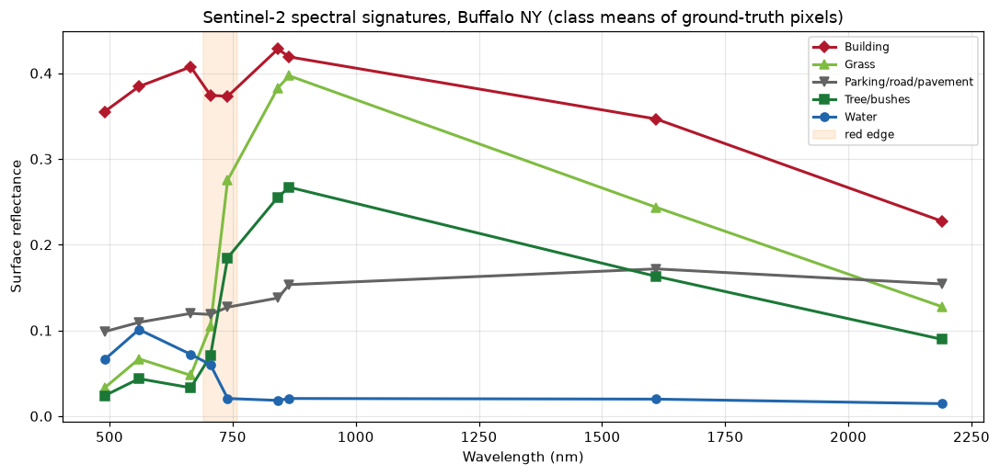

In [15]:
# This code plots the mean spectral reflectance signatures for different land cover classes
# from Sentinel-2 satellite data, using samples labeled in the ground truth.

# Create a new figure and axes for the plot, with specified size
fig, ax = plt.subplots(figsize=(10, 4.8))

# Define plot color and marker styles for each class
style = {
    "Water": ("#2166ac", "o"),
    "Tree/bushes": ("#1b7837", "s"),
    "Grass": ("#7fbc41", "^"),
    "Building": ("#b2182b", "D"),
    "Parking/road/pavement": ("#636363", "v")
}

# Iterate over each class and its mean reflectance values
for cls, row in sig_s2.iterrows():
    # Get color and marker for this class, or use default if not specified
    col, mk = style.get(cls, ("k", "o"))
    # Plot signature: wavelength vs. mean reflectance for this class
    ax.plot(list(S2_NM.values()), row.values, marker=mk, color=col, lw=2, label=cls)

# Highlight the red-edge region in the spectrum
ax.axvspan(690, 760, color="#fdae61", alpha=0.2, label="red edge")

# Set axes labels
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Surface reflectance")  # y label

# Add plot title
ax.set_title("Sentinel-2 spectral signatures, Buffalo NY (class means of ground-truth pixels)")

# Add legend with smaller font size
ax.legend(fontsize=8)

# Adjust layout and display the plot
plt.tight_layout()
plt.show()  # draw

These are surface-reflectance signatures from 1,497 labelled pixels, and each follows the
textbook shape:

* **Vegetation.** Trees and grass absorb red light (reflectance 0.03 to 0.05) and reflect strongly
  in the NIR (0.26 and 0.38). The red edge is visible in the two red-edge bands: grass rises
  from 0.105 at 705 nm to 0.275 at 740 nm and 0.383 at 842 nm. Grass is brighter than the tree
  canopy in the NIR because tree crowns contain shadows. Both drop in the SWIR, where leaf water
  absorbs.
* **Water** (one pond, 53 pixels) is dark in the NIR and SWIR (about 0.02). Its green peak
  (0.10) is higher than the blue, which suggests algae or suspended sediment rather than clear
  water.
* **Buildings** are bright and nearly flat from blue to NIR (0.36 to 0.43): light-coloured flat
  roofs. **Roads and parking lots** are flat and dark (0.10 to 0.17).


### Landsat 8 scene: colour composites

The Landsat 8 Level-1 file stores digital numbers. We first convert the reflective bands to
**top-of-atmosphere reflectance** with the coefficients from the MTL file (the details are in
The *Processing levels: from DN to physical units* section), then display a natural-colour composite (red, green, blue) and a false-colour
composite (NIR, red, green), in which vegetation appears red.


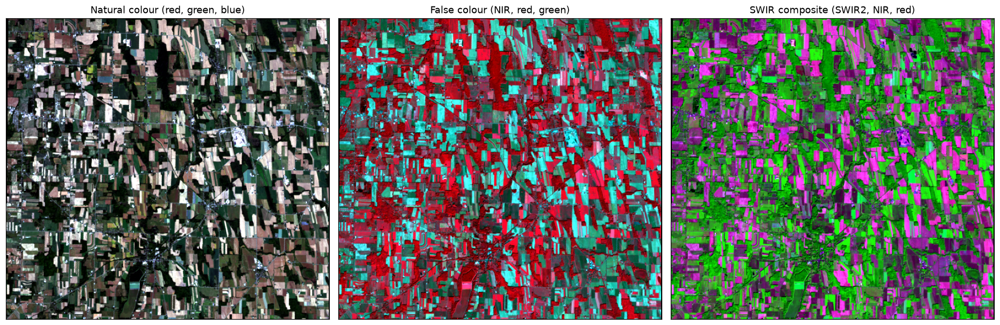

In [16]:
# Select all reflective bands to process from the Landsat 8 band mapping.
# Bands 1-7 and 9 are reflective (the rest are thermal or non-optical), so we keep those.
REFLECTIVE = {b: n for b, n in L8_BANDS.items() if b <= 7 or b == 9}

# For each reflective band, convert the digital number (DN) data to top-of-atmosphere (TOA) reflectance.
# This uses the multiplicative and additive calibration coefficients from the MTL metadata file,
# as well as the sun elevation angle. The resulting reflectance arrays are combined into an xarray Dataset.
toa = xr.Dataset({
    name: rs.optical.toa_reflectance(
        dn[name],
        mtl[f"REFLECTANCE_MULT_BAND_{b}"],
        mtl[f"REFLECTANCE_ADD_BAND_{b}"],
        mtl["SUN_ELEVATION"]
    )
    for b, name in REFLECTIVE.items()
}).rio.write_crs(dn.rio.crs)  # Set the coordinate reference system to match the original data

# Create a single figure with 3 subplots, arranged in one row.
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))

# Display three types of RGB composites using the reflectance data:
# 1. A true-color (natural color) composite: (red, green, blue)
rs.viz.plot_rgb(toa, "true_color", ax=axes[0], title="Natural colour (red, green, blue)")

# 2. A false-color composite, showing NIR, red, and green (vegetation shows up as red).
rs.viz.plot_rgb(toa, ("nir", "red", "green"), ax=axes[1], title="False colour (NIR, red, green)")

# 3. A SWIR composite: SWIR2, NIR, and red (useful for soil and moisture contrasts).
rs.viz.plot_rgb(toa, ("swir22", "nir", "red"), ax=axes[2], title="SWIR composite (SWIR2, NIR, red)")

# Remove axis tick marks for cleaner visual appearance.
for a in axes:
    a.set_xticks([])  # no x ticks
    a.set_yticks([])  # no y ticks

# Optimize layout and display the figure.
plt.tight_layout()
plt.show()  # draw

The subset is a patchwork of farm fields photographed in late September. In the false-colour
image, growing crops, pasture and woodlots are red; harvested or bare fields are cyan and
grey; small towns and roads are bluish grey. In the SWIR composite, vegetation is green and
bare soil is magenta, because dry soil is bright in the SWIR while leaf water absorbs there.

### Spectral indices

Spectral indices turn these contrasts into single numbers. NDVI, $(NIR - Red)/(NIR + Red)$,
is high for vegetation; NDWI, $(Green - NIR)/(Green + NIR)$, is positive for open water; and
NDBI, $(SWIR1 - NIR)/(SWIR1 + NIR)$, is high for built-up and bare surfaces. `geolattice.rsense`
registers more than a hundred indices:


In [17]:
# List all available spectral indices registered in rs.optical
catalog = rs.optical.list_indices()

# Print the total number of registered indices
print(len(catalog), "indices registered")

# Summarize the registered indices by their domain (e.g., vegetation, water, urban, etc.)
# Show a table with the counts for each domain
catalog.groupby("domain").size().sort_values(ascending=False).to_frame("count").T

121 indices registered


domain,vegetation,water,rededge,rgb,burn,urban,soil,snow,other
count,41,20,18,14,9,7,5,4,3


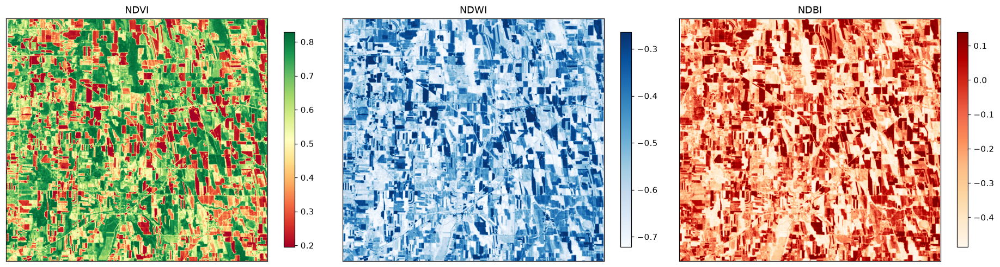

,pixels,% of scene,coastal,blue,green,red,nir,swir16,swir22
Dense vegetation (NDVI > 0.6),140996,51.71,0.114,0.091,0.078,0.053,0.351,0.169,0.081
Harvested / bare fields (NDVI < 0.3),40302,14.78,0.143,0.130,0.129,0.148,0.238,0.289,0.248
Farm ponds (NDWI > 0),129,0.05,0.124,0.103,0.083,0.066,0.062,0.046,0.037


In [18]:
# Compute three common spectral indices (NDVI, NDWI, NDBI) for the scene using the reflectance data.
# - NDVI: Normalized Difference Vegetation Index, highlights vegetation
# - NDWI: Normalized Difference Water Index, highlights water
# - NDBI: Normalized Difference Built-up Index, highlights built-up and bare surfaces
vi = rs.optical.index(toa, ["NDVI", "NDWI", "NDBI"])

# Create a figure with 3 side-by-side subplots to visualize the three indices.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for a, (name, cmap) in zip(  # each panel with an index and its colour map
    axes, [("NDVI", "RdYlGn"), ("NDWI", "Blues"), ("NDBI", "OrRd")]
):
    # Plot each index as an image, using an appropriate colormap and axis title.
    rs.viz.plot_raster(vi[name].rio.write_crs(toa.rio.crs), ax=a, cmap=cmap, title=name)
    a.set_xticks([])  # Remove x-axis ticks for a cleaner look
    a.set_yticks([])  # Remove y-axis ticks

plt.tight_layout()    # Adjust subplot spacing for neatness
plt.show()  # draw

# Define masks to classify pixels into three land cover types:
#   - Dense vegetation: pixels where NDVI > 0.6
#   - Harvested/bare fields: NDVI < 0.3 and not water (NDWI <= 0)
#   - Farm ponds (water): NDWI > 0
masks = {
    "Dense vegetation (NDVI > 0.6)": vi["NDVI"] > 0.6,
    "Harvested / bare fields (NDVI < 0.3)": (vi["NDVI"] < 0.3) & (vi["NDWI"] <= 0),
    "Farm ponds (NDWI > 0)": vi["NDWI"] > 0,
}

# Specify the order of Landsat 8 spectral bands to summarize reflectance
L8_ORDER = ["coastal", "blue", "green", "red", "nir", "swir16", "swir22"]

# For each class (mask), calculate the mean reflectance in each band by masking out pixels outside the class.
# Construct a DataFrame: rows = classes, columns = band reflectances.
sig_l8 = pd.DataFrame(
    {cls: [float(toa[b].where(m).mean()) for b in L8_ORDER] for cls, m in masks.items()},
    index=L8_ORDER,
).T

# Add the count of pixels in each class
sig_l8.insert(0, "pixels", [int(m.sum()) for m in masks.values()])
# Add the percentage of the scene that each class represents
sig_l8.insert(1, "% of scene", [round(float(m.mean()) * 100, 2) for m in masks.values()])

# Present the reflectance statistics rounded to 3 decimals
sig_l8.round(3)

Dense vegetation (NDVI > 0.6) covers 52% of the subset and harvested or bare fields
(NDVI < 0.3) 15%. Their TOA signatures show the same contrasts as the Sentinel-2 ground truth:

* Vegetation has red 0.053 and NIR 0.351.
* Bare fields have red 0.148, NIR 0.238 and SWIR1 0.289. SWIR1 is above NIR, so **NDBI is
  positive for bare soil as well as for buildings**, a well-known limitation of that index.

Open water is almost absent. NDWI is negative everywhere except 129 pixels (0.05%) of small
farm ponds, which are mixed pixels at 30 m. Even their TOA NIR reflectance (0.06) is far
above that of clear water, because of path radiance and the land around them.


## Physics in the data: the Sun's spectrum and atmospheric scattering

Two theoretical results from the *Physical principles* section can be checked against the Landsat scene.

### The solar spectrum hidden in the metadata

The MTL file gives two linear conversions for each band: DN to radiance
($L = M_L\,DN + A_L$) and DN to reflectance without the sun-angle term
($\rho' = M_\rho\,DN + A_\rho$). Both describe the same pixel, so the radiative transfer equation
of the *Radiometric quantities and the radiative transfer equation* section, $\rho' = \pi L d^2 / E_{sun}$, lets us solve for the **exo-atmospheric solar
irradiance** each band sees:

$$E_{sun} = \frac{\pi\,L\,d^2}{\rho'}.$$

Planck's law for a 5,778 K Sun predicts the same quantity: $E_\lambda = \pi B_\lambda(T)\,(R_{sun}/d_{AU})^2$.


,centre (µm),E_sun from MTL (W m⁻² µm⁻¹),"Planck 5,778 K (W m⁻² µm⁻¹)",ratio MTL / Planck
coastal,0.443,1972.318,1727.557,1.142
blue,0.482,2019.631,1788.960,1.129
green,0.561,1861.103,1744.104,1.067
red,0.655,1569.337,1536.074,1.022
nir,0.865,960.359,996.773,0.963
swir16,1.609,238.826,203.072,1.176
swir22,2.201,80.500,74.703,1.078


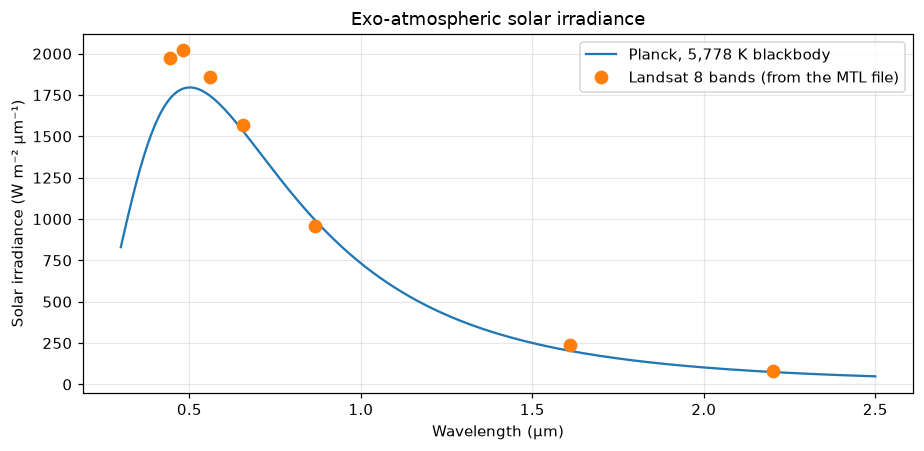

In [19]:
# --- Explanation of the code below ---
# The following code section computes and compares the exo-atmospheric solar irradiance values used in a Landsat 8 scene's metadata (the MTL file)
# to theoretical values computed from Planck's law for a blackbody at the Sun's temperature (~5,778 K).
# This checks how closely the calibration metadata matches the physical solar spectrum.

# 1. Define the center wavelengths (in microns) for each OLI/Landsat 8 band.
OLI_CENTRE = {
    "coastal": 0.443,
    "blue": 0.482,
    "green": 0.561,
    "red": 0.655,
    "nir": 0.865,
    "swir16": 1.609,
    "swir22": 2.201,
}

# 2. Get the Earth-Sun distance for the day of imaging, from the MTL metadata.
d = mtl["EARTH_SUN_DISTANCE"]

# 3. Recover E_sun (exo-atmospheric solar irradiance) for each band using metadata calibration coefficients.
esun = {}
for b, name in REFLECTIVE.items():  # every reflective band
    if name not in OLI_CENTRE:  # skip bands without a centre wavelength
        continue
    # Choose any digital number (DN) value (here 20,000) since the ratio is linear; it cancels out.
    dn_ref = 20000.0
    # Compute radiance at the top of atmosphere using radiometric rescaling.
    L = mtl[f"RADIANCE_MULT_BAND_{b}"] * dn_ref + mtl[f"RADIANCE_ADD_BAND_{b}"]
    # Compute reflectance without correcting for sun angle.
    rho = mtl[f"REFLECTANCE_MULT_BAND_{b}"] * dn_ref + mtl[f"REFLECTANCE_ADD_BAND_{b}"]
    # Rearranged radiative transfer equation gives E_sun.
    esun[name] = np.pi * L * d**2 / rho
# Store these values in a pandas Series.
esun = pd.Series(esun, name="E_sun from MTL (W m⁻² µm⁻¹)")

# 4. Compute the theoretical solar irradiance at each band's wavelength using Planck's law (blackbody at 5,778 K).
#    - Converts wavelengths to meters, applies πB_λ(T), multiplies by the (Sun radius/distance)^2 solid angle, and scales units.
planck_esun = pd.Series(
    {
        n: np.pi * planck(OLI_CENTRE[n] * 1e-6, 5778) * (6.96e8 / 1.496e11) ** 2 * 1e-6
        for n in esun.index
    },
    name="Planck 5,778 K (W m⁻² µm⁻¹)",
)

# 5. Create a DataFrame summarizing the band center wavelengths, MTL irradiance, Planck prediction, and their ratio.
cmp = pd.concat(
    [pd.Series(OLI_CENTRE)[esun.index].rename("centre (µm)"), esun, planck_esun],
    axis=1,
)
# how close the metadata irradiance is to the Planck prediction
cmp["ratio MTL / Planck"] = cmp.iloc[:, 1] / cmp.iloc[:, 2]

# 6. Display the DataFrame, rounded for neatness.
display(cmp.round(3))

# 7. Plot comparison of the MTL (metadata) and theoretical (Planck) exo-atmospheric solar irradiances across wavelengths.
wl_um = np.linspace(0.3, 2.5, 400)
fig, ax = plt.subplots(figsize=(8.5, 4.2))  # one panel
# Plot the Planck blackbody curve (in solar units).
ax.plot(
    wl_um,
    np.pi * planck(wl_um * 1e-6, 5778) * (6.96e8 / 1.496e11) ** 2 * 1e-6,
    label="Planck, 5,778 K blackbody",
)
# Plot the actual band center values derived from the MTL.
ax.plot(
    cmp["centre (µm)"], cmp.iloc[:, 1], "o", ms=8, label="Landsat 8 bands (from the MTL file)"
)
ax.set_xlabel("Wavelength (µm)")  # x label
ax.set_ylabel("Solar irradiance (W m⁻² µm⁻¹)")  # y label
ax.set_title("Exo-atmospheric solar irradiance")  # title
ax.legend()  # legend
plt.tight_layout()  # arrange
plt.show()  # draw

The irradiance implied by the metadata peaks in the blue band at 2,020 W m⁻² µm⁻¹ and falls
to 80 W m⁻² µm⁻¹ at 2.2 µm. That is the solar spectrum, recovered from two lines of
calibration coefficients. The 5,778 K blackbody reproduces its shape to within 2 to 18%, with a
peak near 0.5 µm as Wien's law predicts. The real Sun is not a perfect blackbody: its
photosphere emits from different temperatures at different wavelengths, and absorption lines
are averaged over each band. That is why measured solar spectra, not Planck curves, are used
in calibration.

### Rayleigh scattering in the darkest pixels

The darkest pixels of a scene reflect almost nothing at the surface, so most of their TOA
signal is atmospheric path radiance. If molecular (Rayleigh) scattering dominates, the
dark-object reflectance should fall steeply with wavelength. The **dark object subtraction**
method (DOS1, Chavez 1996; `rs.optical.dos1`) uses exactly this signal for a first-order
atmospheric correction.

The method needs genuinely dark targets in every band it corrects: deep clear water or deep
shadow. This farmland subset has no lake, and in the visible bands the darkest pixels are
dense crops and woodland, which absorb blue and red light for photosynthesis. In the NIR and
SWIR the same vegetation is bright, so the darkest pixels there are not dark at all. We
therefore test the scattering law on the visible bands only.


Power-law fit over the visible bands: dark reflectance ∝ λ^-2.75  (pure Rayleigh: λ^-4)


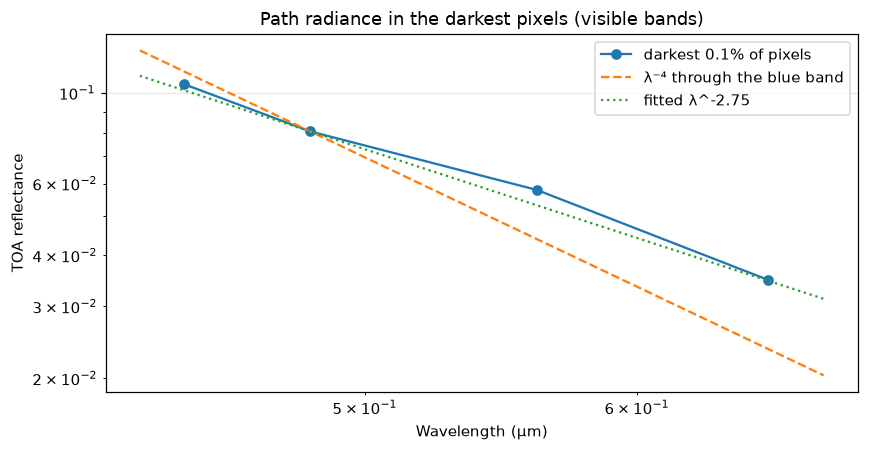

,coastal,blue,green,red,nir,swir16,swir22
TOA dark object,0.1050,0.0805,0.0579,0.0349,0.1275,0.0650,0.0308
after DOS1,0.0107,0.0108,0.0130,0.0118,0.1088,0.0636,0.0321
median TOA,0.1175,0.0963,0.0862,0.0710,0.2959,0.1954,0.1106
median after DOS1,0.0232,0.0266,0.0413,0.0479,0.2771,0.1940,0.1119


In [20]:
# Select the four visible Landsat 8 (OLI) bands by name.
vis = ["coastal", "blue", "green", "red"]

# For each band, calculate the 0.1th percentile of Top-Of-Atmosphere (TOA) reflectance values,
# representing the darkest pixels (potentially shadow or water). Store these in a pandas Series.
dark = pd.Series(
    {b: float(np.nanpercentile(toa[b].values, 0.1)) for b in OLI_CENTRE},
    name="dark-object TOA reflectance (0.1th percentile)"
)

# Fit a straight line in log-log space (power-law) to the relationship between wavelength and
# dark-object reflectance across the visible bands, to see how reflectance falls off with wavelength.
# This gives a slope which, for pure Rayleigh scattering, should be -4.
slope, intercept = np.polyfit(
    np.log([OLI_CENTRE[b] for b in vis]),
    np.log(dark[vis].values),
    1
)
# slope of the fitted power law
print(f"Power-law fit over the visible bands: dark reflectance ∝ λ^{slope:.2f}  (pure Rayleigh: λ^-4)")

# Plot the results:
fig, ax = plt.subplots(figsize=(8, 4.2))

# Plot the measured dark-object (0.1th percentile) reflectances vs wavelength for the visible bands,
# using a log-log scale.
ax.loglog([OLI_CENTRE[b] for b in vis], dark[vis].values, "o-", label="darkest 0.1% of pixels")

# Create an array of wavelengths between the blue and red bands (in microns).
lam = np.linspace(0.43, 0.68, 50)

# Plot the theoretical Rayleigh scattering line (λ^-4) normalised to the blue band.
ax.loglog(
    lam,
    dark["blue"] * (lam / OLI_CENTRE["blue"]) ** -4,
    "--",
    label="λ⁻⁴ through the blue band"
)

ax.set_xlabel("Wavelength (µm)")  # x label
ax.set_ylabel("TOA reflectance")  # y label

# Plot the fitted power-law line using the computed slope, again normalised to the blue band.
ax.loglog(
    lam,
    dark["blue"] * (lam / OLI_CENTRE["blue"]) ** slope,
    ":",
    label=f"fitted λ^{slope:.2f}"
)

ax.set_title("Path radiance in the darkest pixels (visible bands)")  # title
ax.legend()  # legend
plt.tight_layout()  # arrange
plt.show()  # draw

# Apply the Dark Object Subtraction (DOS1) atmospheric correction to all OLI bands.
corrected = rs.optical.dos1(toa[list(OLI_CENTRE)])

# Construct a dataframe comparing the dark-object and median reflectance before and after correction.
pd.DataFrame({
    "TOA dark object": dark,
    "after DOS1": pd.Series({b: float(np.nanpercentile(corrected[b].values, 0.1)) for b in OLI_CENTRE}),
    "median TOA": pd.Series({b: float(toa[b].median()) for b in OLI_CENTRE}),
    "median after DOS1": pd.Series({b: float(corrected[b].median()) for b in OLI_CENTRE})
}).round(4).T

Across the visible bands the dark-object reflectance falls as $\lambda^{-2.75}$: from 0.105 in
the coastal band to 0.035 in the red. That is steeper than aerosol (Mie) scattering alone,
but shallower than the pure Rayleigh $\lambda^{-4}$. Two reasons:

* Aerosols add a flatter component.
* The darkest pixels here are vegetation, not water, so they still carry some surface
  reflectance.

DOS1 removes most of this haze. It lowers the median blue reflectance from 0.096 to 0.027 and
the coastal band from 0.118 to 0.023, which are typical surface values for vegetated land. In
the NIR it subtracts 0.019, but the darkest NIR pixels in this scene are ponds and vegetation
rather than haze, so that correction removes real signal. In the SWIR it changes almost
nothing.

DOS is therefore a quick fix for the visible bands when a scene has dark targets. Level-2
surface reflectance (the *Level-2 surface reflectance* section) is the better starting point.


## The four resolutions

Every sensor is a compromise between four kinds of resolution:

| Resolution | Question it answers | Landsat 8/9 | Sentinel-2 | MODIS |
|---|---|---|---|---|
| **Spatial** | How small an object can be seen? | 30 m (15 m pan, 100 m thermal) | 10, 20, 60 m | 250, 500, 1000 m |
| **Spectral** | How many bands, and how narrow? | 11 bands | 13 bands | 36 bands |
| **Temporal** | How often is a place revisited? | 16 days (8 with both) | 5 days (two satellites) | 1 to 2 days |
| **Radiometric** | How finely is brightness quantized? | 12-bit (Landsat 9: 14-bit), stored 16-bit | 12-bit | 12-bit |

Improving one usually costs another: MODIS sees the whole planet daily because its pixels are
large, while Sentinel-2's 10 m pixels need five days to cover the globe.

### Spatial resolution

We simulate coarser sensors by block-averaging the 10 m Sentinel-2 image to 30 m (Landsat)
and 250 m (MODIS). Each coarse pixel is a mixture of everything inside it: a **mixed pixel**.


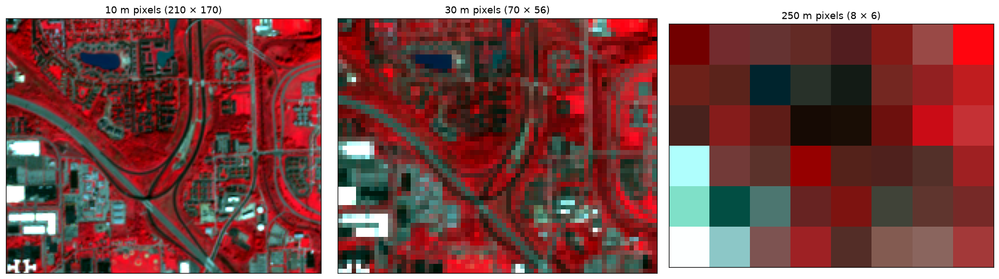

In [21]:
# Create a figure with 3 horizontal subplots, sized appropriately for display.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

# Loop through each subplot axis and corresponding coarsening factor:
# f = 1 shows the original 10m Sentinel-2 image,
# f = 3 simulates Landsat resolution (~30m, by averaging 3x3 blocks),
# f = 25 simulates a coarse MODIS-like pixel (~250m, by averaging 25x25 blocks).
for a, f in zip(axes, [1, 3, 25]):
    if f == 1:  # first panel
        # No coarsening; use original image.
        img = s2
    else:
        # Coarsen image by the given factor, trimming edges,
        # then take mean for each coarse pixel and restore CRS info.
        img = s2.coarsen(x=f, y=f, boundary="trim").mean().rio.write_crs(s2.rio.crs)
    # Plot the image in false color (NIR, red, green), set the subplot title
    # with the simulated pixel size and dimensions.
    rs.viz.plot_rgb(
        img, ("nir", "red", "green"), ax=a,
        title=f"{10 * f} m pixels ({img.sizes['x']} × {img.sizes['y']})"
    )
    # Remove x/y axis ticks for clean output presentation.
    a.set_xticks([]); a.set_yticks([])

# Adjust subplot layout for clarity and show the figure.
plt.tight_layout()
plt.show()  # draw

At 10 m the interchange, individual buildings, parking lots and the pond in the upper left
are sharp. At 30 m (Landsat) the pond and the main roads remain, but buildings merge with the
lawns around them. At 250 m (MODIS) the whole 2 km area is only 48 mixed pixels: one darker
pixel hints at the pond, and the land cover can only be described as fractions.

### Spectral resolution

Spectral resolution decides which materials can be told apart. Trees and grass are both green
vegetation; the table compares how far apart their mean signatures are in each band, relative
to the variation within the classes (a simple separability measure,
$|\mu_1 - \mu_2| / \sqrt{(s_1^2 + s_2^2)/2}$).


In [22]:
# Create a new pandas Series that maps numeric class labels y to their descriptive class names using the 'classes' dictionary, and index it with the same indices as X.
lab = pd.Series(y, index=X.index).map(classes)

# Split the DataFrame X into two groups: one for samples labeled as "Tree/bushes" and another for samples labeled as "Grass".
a = X[lab == "Tree/bushes"]
b = X[lab == "Grass"]  # grass pixels

# Calculate the separability between the "Tree/bushes" and "Grass" classes for each Sentinel-2 band.
# For each band:
#   1. Compute the difference in mean values between the classes.
#   2. Take the absolute value of the difference.
#   3. Divide by the pooled standard deviation (the square root of the average variance of the two classes).
# This gives a measure of how distinct the two classes are in each band.
sep = (
    (a[list(S2_NM)].mean() - b[list(S2_NM)].mean()).abs()
    / np.sqrt((a[list(S2_NM)].var() + b[list(S2_NM)].var()) / 2)
).rename("tree vs grass separability")

# Format the results to two decimal places, convert to a single-row DataFrame, and display.
sep.round(2).to_frame().T

,blue,green,red,rededge1,rededge2,nir,nir08,swir16,swir22
tree vs grass separability,0.56,1.41,0.63,1.99,2.38,2.04,2.11,3.94,1.7


In the visible bands trees and grass are barely separable (0.56 in blue, 0.63 in red): both
absorb for photosynthesis. Separability rises to 2.0 to 2.4 in the red-edge and NIR bands, where
canopy structure differs. It is highest in SWIR1 (3.9), which responds to leaf water and
shadow. The narrow red-edge band at 740 nm (2.38) separates them better than the broad NIR
band (2.04). An RGB camera would struggle to tell these two classes apart; a multispectral
sensor with red-edge and SWIR bands does not.

### Radiometric resolution

Radiometric resolution is the number of distinct brightness levels, $2^{bits}$. Landsat 8
records 12 bits (4,096 levels) and stores them as 16-bit integers scaled to 0 to 65,535. Fewer
levels cause visible banding, most of all in dark, low-contrast targets such as water.


 1-bit →      2 levels
 4-bit →     16 levels
 8-bit →    256 levels
12-bit →  4,096 levels
16-bit → 65,536 levels
NIR DN range in this subset: 5290–27590; distinct values: 14,190


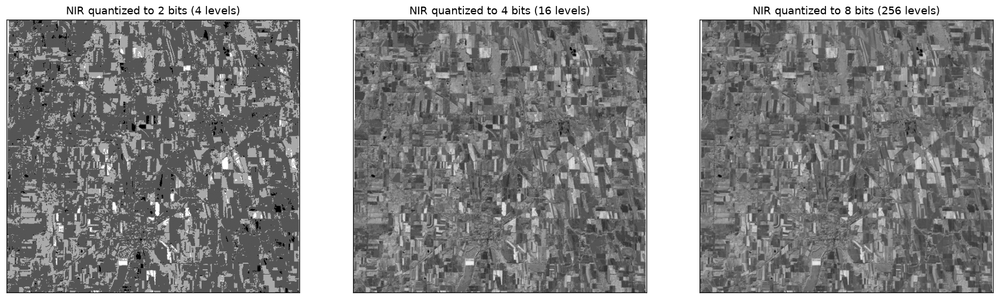

In [23]:
# Loop over typical radiometric resolutions (number of bits per pixel)
for bits in (1, 4, 8, 12, 16):
    # For each bit depth, print the corresponding number of brightness levels
    print(f"{bits:2d}-bit → {2**bits:6,d} levels")

# Extract the digital number (DN) values for the NIR (near-infrared) band
nir_dn = dn["nir"].values

# Filter out any invalid (non-finite) pixel values
valid = nir_dn[np.isfinite(nir_dn)]

# Print the range of NIR DN values and how many unique values are present
print(
    f"NIR DN range in this subset: {valid.min():.0f}–{valid.max():.0f}; "
    f"distinct values: {np.unique(valid).size:,}"
)

# Quantize NIR DN values to different bit depths (simulating reduced radiometric resolution).
# This is done for 2, 4, and 8 bits as examples, using simple linear scaling.
q = {
    bits: np.floor((nir_dn - valid.min()) / (valid.max() - valid.min() + 1) * 2**bits)
    for bits in (2, 4, 8)
}

# Visualize the quantized images
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (bits, arr) in zip(axes, q.items()):  # each bit depth with its quantised image
    ax.imshow(arr, cmap="gray")  # show it in grey
    ax.set_title(f"NIR quantized to {bits} bits ({2**bits} levels)")  # title with the number of levels
    ax.set_xticks([])  # no x ticks
    ax.set_yticks([])  # no y ticks
plt.tight_layout()  # arrange
plt.show()  # draw

### Temporal resolution

Temporal resolution cannot be seen in a single scene, but it decides what can be monitored.
Crop growth needs observations every few days to weeks, floods need hours to days, and
cloud cover reduces the usable revisit: the full Landsat scene used here was 18.8% cloudy
(this subset happens to be clear), and in humid regions a 16-day revisit often yields only one
or two clear views a month. Combining sensors
(Landsat + Sentinel-2 in the Harmonized Landsat Sentinel-2 product, `rs.optical.load_hls`),
adding SAR, or fusing coarse daily data with fine sparse data (`rs.fusion.starfm`) are the
usual remedies. The time-series notebooks (07_06) cover time-series analysis.


## Passive and active sensors

**Passive** sensors record natural energy: reflected sunlight (optical) or emitted heat
(thermal). Everything in the sections from *Spectral signatures from real images* to *The four resolutions* is passive.

**Active** sensors send their own pulse and time the echo:

- **Radar (SAR)** transmits microwaves that pass through clouds and work at night, which is why
  Sentinel-1 is the workhorse for flood mapping in the monsoon. It measures *backscatter*,
  usually expressed in decibels (dB).
- **Lidar** transmits laser pulses and records return times, giving precise 3-D point clouds of
  terrain and vegetation structure.

Radar backscatter spans several orders of magnitude, so it is usually shown in decibels,
$\sigma^0_{dB} = 10 \log_{10}(\sigma^0)$:


In [24]:
# Define typical radar backscatter (sigma0, linear scale) for various surfaces
surfaces = {
    "Calm water": 0.001,
    "Bare field": 0.03,
    "Grassland": 0.08,
    "Forest": 0.15,
    "Urban corner reflector": 2.0
}

# Convert linear sigma0 values to decibel (dB) using the SAR utility function
# This helps visualize the large dynamic range in radar backscatter for each surface type
db = rs.sar.to_db(np.array(list(surfaces.values())))

# Create a DataFrame showing both the original (linear) and dB-scaled sigma0 values for easy comparison
pd.DataFrame(
    {
        "sigma0 (linear)": list(surfaces.values()),
        "sigma0 (dB)": db.round(1)
    },
    index=surfaces.keys()
)

,sigma0 (linear),sigma0 (dB)
Calm water,0.001,-30.0
Bare field,0.030,-15.2
Grassland,0.080,-11.0
Forest,0.150,-8.2
Urban corner reflector,2.000,3.0


Calm water acts as a mirror and sends the pulse away from the sensor (−30 dB, very dark),
while buildings form corner reflectors that send it straight back (+3 dB, very bright). The
same physical contrast drives SAR flood mapping (`rs.sar.flood_map`) in the radar notebooks (07_03).


## Processing levels: from DN to physical units

Raw sensor counts pass through a chain of corrections before analysis:

| Level | Content | Example |
|---|---|---|
| L0 | Raw instrument data | Downlinked telemetry |
| L1 | Calibrated, geolocated **radiance** or TOA reflectance (as DN with scale factors) | Landsat Collection 1/2 Level-1, Sentinel-2 L1C |
| L2 | Geophysical variables: **surface reflectance**, surface temperature, backscatter | Landsat C2 Level-2, Sentinel-2 L2A, MOD09 |
| L3 | Gridded, composited or aggregated products | MOD13 16-day NDVI |
| L4 | Model outputs that combine data | GPP, soil moisture analyses |

For Landsat Level-1 the conversions use coefficients from the scene's metadata (`*_MTL.txt`):

- Radiance: $L_\lambda = M_L \cdot DN + A_L$ (`rs.optical.radiance`)
- TOA reflectance: $\rho = (M_\rho \cdot DN + A_\rho) / \sin(\theta_{SE})$, with sun elevation
  $\theta_{SE}$ (`rs.optical.toa_reflectance`)
- Brightness temperature (thermal bands): $BT = K_2 / \ln(K_1/L_\lambda + 1)$
  (`rs.optical.brightness_temperature`), the inverse of Planck's law for the band.

### Reflective bands


In [25]:
# This block retrieves the calibration coefficients for each reflective band (used to convert between DN, radiance, and TOA reflectance),
# and then summarizes the typical values for each band over the scene.

# Collect the multiplicative/additive coefficients ("M" and "A") for both reflectance ("rho") and radiance ("L")
# from the metadata (MTL) file for each reflective band. These are necessary for conversions:
# - between digital number (DN) and top-of-atmosphere (TOA) reflectance
# - between DN and radiance.
# The coefficients are organized into a DataFrame for easy viewing.
coef = pd.DataFrame({
    name: {
        "M_rho": mtl[f"REFLECTANCE_MULT_BAND_{b}"],   # reflectance gain
        "A_rho": mtl[f"REFLECTANCE_ADD_BAND_{b}"],    # reflectance offset
        "M_L": mtl[f"RADIANCE_MULT_BAND_{b}"],        # radiance gain
        "A_L": mtl[f"RADIANCE_ADD_BAND_{b}"]          # radiance offset
    }
    for b, name in REFLECTIVE.items()
}).T
display(coef)  # show the calibration coefficients

# For a subset of common bands, compute and summarize the central tendency of their DN, radiance, and TOA reflectance values.
# This illustrates the typical pixel values encountered in this scene after calibration.
rows = []
for name in ["blue", "red", "nir", "swir16"]:  # four representative bands
    # Find the band number in L8_BANDS that matches the band name
    b = next(k for k, v in L8_BANDS.items() if v == name)
    # Convert DN to radiance using the calibration coefficients from the metadata
    rad = rs.optical.radiance(
        dn[name],
        mtl[f"RADIANCE_MULT_BAND_{b}"],
        mtl[f"RADIANCE_ADD_BAND_{b}"]
    )
    # Gather median values for DN, radiance, and TOA reflectance for this band
    rows.append({
        "band": name,
        "median DN": float(dn[name].median()),
        "median radiance": float(rad.median()),
        "median TOA reflectance": float(toa[name].median())
    })

# Display the results as a DataFrame (bands as index), rounding for clarity.
pd.DataFrame(rows).set_index("band").round(3)

,M_rho,A_rho,M_L,A_L
coastal,0.00002,-0.1,0.012503,-62.51346
blue,0.00002,-0.1,0.012803,-64.01454
green,0.00002,-0.1,0.011798,-58.98885
red,0.00002,-0.1,0.009949,-49.74272
nir,0.00002,-0.1,0.006088,-30.44007
swir16,0.00002,-0.1,0.001514,-7.57017
swir22,0.00002,-0.1,0.000510,-2.55155
cirrus,0.00002,-0.1,0.002379,-11.89667


,median DN,median radiance,median TOA reflectance
band,,,
blue,8247.0,41.572,0.096
red,7392.0,23.797,0.071
nir,14972.0,60.709,0.296
swir16,11585.0,9.970,0.195


### Thermal band: brightness temperature

Band 10 (10.9 µm) records emitted radiance. Inverting Planck's law with the band constants
$K_1$ and $K_2$ from the MTL file gives the **brightness temperature**: the temperature a
blackbody would need to produce the measured radiance. Correcting for emissivity (estimated
from NDVI, `rs.optical.emissivity_ndvi`) turns it into land surface temperature
(`rs.optical.landsat_lst`, optical notebooks 07_02).


K1 = 774.8853, K2 = 1321.0789


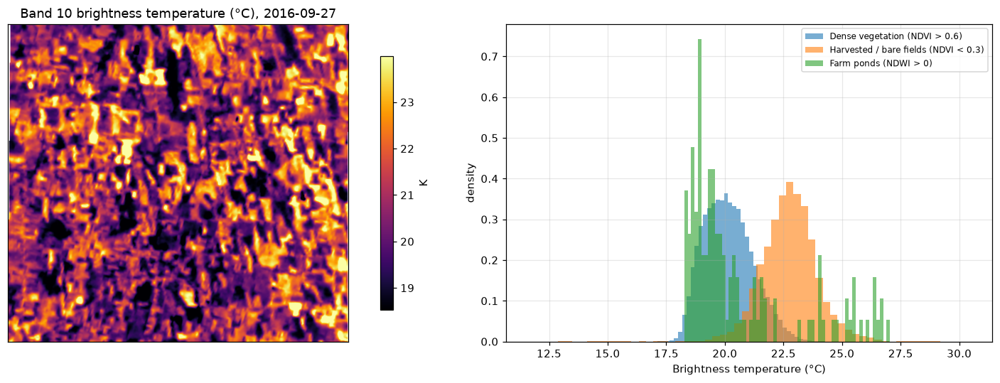

,median BT (°C),pixels
Dense vegetation (NDVI > 0.6),20.1,140996.0
Harvested / bare fields (NDVI < 0.3),22.8,40302.0
Farm ponds (NDWI > 0),19.6,129.0


In [26]:
# Calculate at-sensor radiance for thermal Band 10 using the calibration coefficients from the MTL metadata
rad10 = rs.optical.radiance(
    dn["tir1"],                     # Digital numbers (DN) for thermal infrared band (Band 10)
    mtl["RADIANCE_MULT_BAND_10"],   # Radiance multiplicative scaling factor from metadata
    mtl["RADIANCE_ADD_BAND_10"]     # Radiance additive scaling factor from metadata
)

# Convert the radiance to brightness temperature (in Kelvin) using Planck's law and sensor-specific constants
bt = rs.optical.brightness_temperature(
    rad10,                          # at-sensor radiance for Band 10
    mtl["K1_CONSTANT_BAND_10"],     # K1 constant from metadata
    mtl["K2_CONSTANT_BAND_10"]      # K2 constant from metadata
)

# Convert brightness temperature from Kelvin to Celsius, and assign the coordinate reference system
bt_c = (bt - 273.15).rio.write_crs(dn.rio.crs)

# Display the K1 and K2 constants for reference
print(f"K1 = {mtl['K1_CONSTANT_BAND_10']}, K2 = {mtl['K2_CONSTANT_BAND_10']}")

# Set up a figure with two panels: map and histogram
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.3, 1]})

# Show the brightness temperature map on the left, colored by temperature
rs.viz.plot_raster(
    bt_c, ax=axes[0], cmap="inferno",
    title="Band 10 brightness temperature (°C), 2016-09-27"
)
axes[0].set_xticks([]); axes[0].set_yticks([])  # no ticks on the image panel

# Plot a histogram of brightness temperature for each land cover class on the right
lc = masks  # Dictionary mapping class names to boolean masks
for name, m in lc.items():  # each land-cover class and its mask
    v = bt_c.where(m).values.ravel()  # Extract temperature values where mask is True
    axes[1].hist(  # histogram of its brightness temperatures
        v[np.isfinite(v)], bins=60, alpha=0.6, density=True, label=name
    )
axes[1].set_xlabel("Brightness temperature (°C)")  # x label
axes[1].set_ylabel("density")  # y label
axes[1].legend(fontsize=8)  # legend

# Adjust layout and display the plots
plt.tight_layout(); plt.show()

# Summarize the results: For each land cover class, report the median brightness temperature (°C) and pixel count
pd.DataFrame({
    name: {
        "median BT (°C)": float(bt_c.where(m).median()),
        "pixels": int(m.sum())
    }
    for name, m in lc.items()
}).T.round(1)

On this late-September morning (scene time 15:51 UTC, about 11:50 local), harvested and bare
fields were the warmest surfaces, with a median brightness temperature of 22.8 °C. Dense
vegetation was 2.7 °C cooler (20.1 °C), because transpiring leaves spend energy evaporating
water. The farm ponds (19.6 °C, 129 mixed pixels) were among the coolest. The map is blockier
than the reflective bands because TIRS measures at 100 m and the product is resampled to
30 m.

Brightness temperature is not yet land surface temperature. It ignores emissivity, which
here is below 1, and atmospheric absorption, so it usually underestimates the true surface
temperature by a few degrees.

### Level-2 surface reflectance

Most analysis today starts from **Level-2 surface reflectance**, which is already corrected for
the atmosphere. These products are stored as scaled integers, and `rs.optical.scale` applies
the right factors per sensor (for Landsat Collection 2: $DN \times 2.75\times10^{-5} - 0.2$).
We read a 600 × 600 pixel window from the Landsat 9 Level-2 scene.


In [27]:
# Define the directory and scene ID for the Landsat 9 Level-2 Surface Reflectance product.
L9_DIR = DATA / "LC09_L2SP_138043_20221216_20221223_02_T1"
L9_ID = "LC09_L2SP_138043_20221216_20221223_02_T1"  # the scene ID

# Define a window to select a 600x600 pixel subset from the full scene
win = dict(y=slice(2400, 3000), x=slice(2400, 3000))

# Read each required surface reflectance band file (bands 2, 3, 4, 5, 6) from disk,
# drop the redundant 'band' dimension, select the chosen window,
# and load all pixel values into memory.
l2 = xr.Dataset({
    f"SR_B{b}": rs.read(L9_DIR / f"{L9_ID}_SR_B{b}.TIF", masked=False, chunks={})
                  .squeeze("band", drop=True)
                  .isel(**win)
                  .load()
    for b in (2, 3, 4, 5, 6)
})

# Convert the raw digital numbers (DNs) in l2 to surface reflectance values 
# using the correct scaling for Landsat Collection 2.
sr = rs.optical.scale(l2, sensor="landsat")

# Print which sensor was recognized and used for scaling (metadata compatibility).
print("sensor recognised as:", sr.attrs.get("pyrsense:sensor"))

# Build and display a DataFrame summarizing, for each band:
# - the median raw DN value (from the original data)
# - the median surface reflectance (after scaling)
# and round the numbers to four decimal places for clarity.
pd.DataFrame(
    {
        "DN (median)": {v: float(l2[v].median()) for v in l2.data_vars},
        "surface reflectance (median)": {v: float(sr[v].median()) for v in sr.data_vars}
    }
).round(4)
         

sensor recognised as: landsat


,DN (median),surface reflectance (median)
SR_B2,9869.0,0.0714
SR_B3,11314.0,0.1111
SR_B4,11131.0,0.1061
SR_B5,15213.0,0.2184
SR_B6,13821.0,0.1801


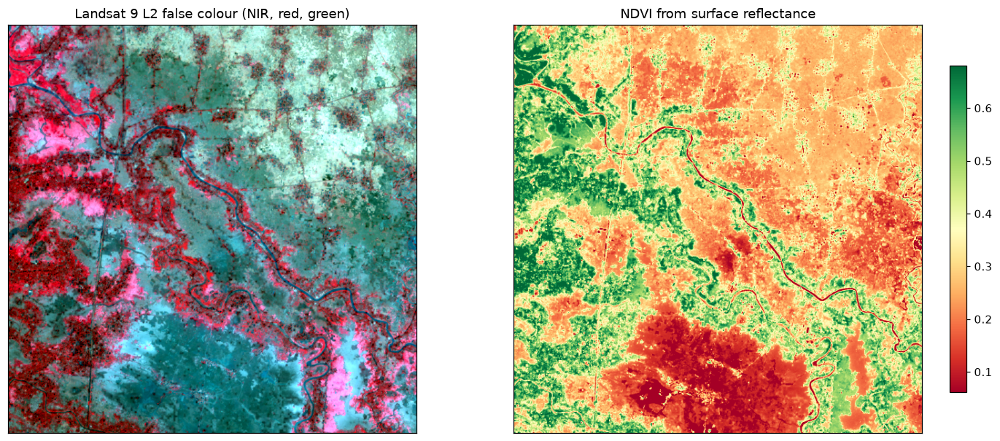

NDVI median 0.29, 5th–95th percentile 0.11 to 0.63


In [28]:
# Calculate the NDVI (Normalized Difference Vegetation Index) from the surface reflectance data.
ndvi_l9 = rs.optical.index(sr, "NDVI")

# Set up a figure with two side-by-side subplots, with a specific size.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))

# Plot a false color image (NIR, red, green) of the Level-2 Landsat 9 scene, showing healthy vegetation in red hues.
rs.viz.plot_rgb(
    sr,
    ("SR_B5", "SR_B4", "SR_B3"),
    ax=axes[0],
    title="Landsat 9 L2 false colour (NIR, red, green)"
)

# Plot the NDVI raster in the second subplot, using a green-yellow-red color map.
# The NDVI layer is assigned the same coordinate reference system as the original data.
rs.viz.plot_raster(
    ndvi_l9.rio.write_crs(l2.rio.crs),
    ax=axes[1],
    cmap="RdYlGn",
    title="NDVI from surface reflectance"
)

# Remove axis tick marks for a cleaner look on both subplots.
for a in axes:
    a.set_xticks([])  # no x ticks
    a.set_yticks([])  # no y ticks

# Adjust the layout to avoid overlap and display the figure.
plt.tight_layout()
plt.show()  # draw

# Print descriptive statistics for NDVI within the image window:
# median value and the range from 5th to 95th percentile (to summarize variability).
print(
    f"NDVI median {float(ndvi_l9.median()):.2f}, 5th–95th percentile "
    f"{float(ndvi_l9.quantile(0.05)):.2f} to {float(ndvi_l9.quantile(0.95)):.2f}"
)
 

`rs.optical.scale` recognised the Collection 2 band names and converted, for example, a
median DN of 9,869 in the blue band to a surface reflectance of 0.071. No sun-angle or
metadata file is needed, because the atmospheric correction was done by USGS.

The 18 × 18 km window in northwestern Bangladesh was imaged in December, in the dry season. A
meandering river runs from the upper left to the lower right. Green vegetation along its
floodplain and in the west has NDVI 0.5 to 0.65, while the dry fallow and harvested land to the
east and south has NDVI 0.1 to 0.3 (median 0.29 over the window).


## Summary and exercises


**Key ideas**

- Remote sensing turns measured radiance into physical quantities and then into information,
  through a chain of source, atmosphere, target, sensor and processing.
- Optical sensors (0.4 to 3 µm) measure reflected sunlight; thermal sensors (8 to 14 µm) measure
  emitted energy; radar and lidar supply their own illumination.
- The atmosphere scatters (Rayleigh ∝ λ⁻⁴) and absorbs; sensors look through its windows, and
  atmospheric correction removes path radiance.
- Spectral signatures (water, vegetation, built surfaces) are the basis of every spectral index
  and classifier.
- Spatial, spectral, temporal and radiometric resolution trade off against each other.
- Analysis-ready data are Level-2 surface reflectance, surface temperature or calibrated
  backscatter in physical units.
- `geolattice.rsense` covers the whole workflow, from data access to deep learning, on CPU or GPU.

**What the data showed**

- Sentinel-2 ground truth reproduced the textbook signatures, including the red edge
  (grass: 0.105 → 0.275 → 0.383 from 705 to 842 nm).
- The Landsat 8 metadata alone recovered the solar spectrum, within 2 to 18% of a 5,778 K
  blackbody.
- Path radiance in the visible bands fell as λ^−2.75, between Rayleigh and aerosol scattering.
  DOS1 removed most of it, but should not be trusted in bands without dark targets.
- Bare fields were 2.7 °C warmer than transpiring vegetation in brightness temperature.
- Red-edge and SWIR bands separated trees from grass four to six times better than the
  visible bands.

**Exercises**

1. Use `planck()` to find the peak wavelength of a 600 K lava flow. Which Landsat band would
   detect it best?
2. Add the Sentinel-2 signature of a sixth material by digitising a polygon (for example a
   sports field or a parking lot) and passing it to `rs.classify.extract_samples`.
3. Compute `"SAVI"`, `"MNDWI"` and `"NBR"` for the Landsat 8 scene with `rs.optical.index` and
   compare their maps with NDVI and NDWI.
4. Repeat the *Rayleigh scattering in the darkest pixels* section on band 9 (cirrus, 1.37 µm). What do its brightest pixels show, and why?
5. Compute the brightness temperature from band 11 and compare it with band 10 over the
   vegetation and the harvested fields.
   The difference is the basis of split-window LST algorithms.
6. Use the [PyGIS Explorer app](https://zia207-pygis-explorer-app-ou8ehd.streamlit.app/) or
   `rs.access.stac_search` to find a recent cloud-free Sentinel-2 L2A scene of your area, and
   plot its spectral signatures.

**References**

- Chavez, P.S. (1996). Image-based atmospheric corrections, revisited and improved.
  *Photogrammetric Engineering & Remote Sensing* 62(9), 1025 to 1036.
- Jensen, J.R. (2007). *Remote Sensing of the Environment: An Earth Resource Perspective*, 2nd ed. Pearson.
- Lillesand, T., Kiefer, R.W. & Chipman, J. (2015). *Remote Sensing and Image Interpretation*, 7th ed. Wiley.
- Schott, J.R. (2007). *Remote Sensing: The Image Chain Approach*, 2nd ed. Oxford University Press.
- U.S. Geological Survey (2019). *Landsat 8 (L8) Data Users Handbook*, version 5.0. LSDS-1574.
- European Space Agency (2015). *Sentinel-2 User Handbook*. ESA Standard Document.

**Next:** Notebook 09_01_01 sets up the Python geospatial environment and introduces the CPU/GPU backend
of `geolattice.rsense`.
